#**Using Python libraries for Handling WaPOR Data**

[![](https://raw.githubusercontent.com//wateraccounting/WaPORMOOC/main/images/colab-badge.png)](https://colab.research.google.com/github/wateraccounting/WaPORMOOC/blob/main/3_Python_for_WaPOR/N02_Temporal_Aggregation.ipynb?target="_blank")

#Notebook 2 : Temporal data aggregation

In this Notebook we will show you how to do temporal aggregation of WaPOR data.  

The steps we are going to follow are:
1. Install and load necessary packages to manage rasterfiles
2. Load the .zip file with the required data for the Wad Helal area to this session (see details below)
3. Unzip the files
4. Open and inspect one .tif file
>+Exercise 1 (answers needed for the MOOC quiz)
5. Perform the temporal aggregation (sum) of the dekadal AETI & export result to local drive
>+Exercise 2 (answers needed for the MOOC quiz)
6. More detailed temporal aggregation by date
>+Exercise 3 (answers needed for the MOOC quiz)
7. Open and inspect the result in QGIS
>+Quiz question (answer needed for the MOOC quiz)

**Data needed:**

For the exercises of the [MOOC Python for geospatial analyses using WaPOR data](https://ocw.un-ihe.org/course/view.php?id=272) you can download the data using the file  \"Wad_Helal.geojson\" located in the data folder of [WaPORMOOC](https://github.com/wateraccounting/WaPORMOOC/tree/main/data) for the area (Wad Helal) using the [Download_WaPORv3_Data Notebook](https://github.com/wateraccounting/WaPORMOOC/blob/main/1_WaPOR_download_colab/Download_WaPORv3_Data.ipynb) :
1. **Area:** Wad Helal in the Gezira Irrigation Scheme.
2. **Type of Data:** AETI
3. **Spatial resolution:** Level 3
4. **Temporal resolution:** dekadal
5. **Start date:** 2022-10-01
6. **End date:** 2023-04-30

 © 2024 IHE Delft Licenced under CC BY SA Creative Commons

---

### **Step 1**


In [1]:
!pip install rioxarray --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.7 MB/s eta 0:00:00


In [2]:
import os
import glob
import datetime
import xarray as xr
import rioxarray as rio
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

### **Step 2 - Create a .zip file/Upload an existing .zip files**
We will now upload a .zip file containing a series of .tif files to our session: data.zip.
   
Execute the command below and navigate to where you have saved the .zip file from Topic3_N01 in your local drive.

(If you are uploading your own .tif files, you can first create a .zip archive from these files, you may need to install compression software such as 7zip (https://www.7-zip.org/) or WinRAR (https://www.win-rar.com/) to perform this operation.)

In [3]:
#To upload file.
uploaded = files.upload()

Saving data.zip to data.zip


### **Step 3 - Unzip files**
Unzip the file you have uploaded.
The command is:
 !unzip 'file_path.zip' -d 'folder_to_unzip_path'
Replace the file name in the cell below with the name of your own file. You can find the path to your file by clicking on the 3 dots next to the file name in your file explorer to the left and selecting *Copy path*. (If you do not see your files to the left, click on the folder icon to expand the Files panel).


In [4]:
# unzip the uploaded zipfile
!unzip '/content/data.zip' -d '/content/'

Archive:  /content/data.zip
   creating: /content/content/output/
   creating: /content/content/output/L1-T-D/
  inflating: /content/content/output/L1-T-D/Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2021-06-01.tif  
  inflating: /content/content/output/L1-T-D/Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2021-01-21.tif  
  inflating: /content/content/output/L1-T-D/Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2023-06-21.tif  
  inflating: /content/content/output/L1-T-D/Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2022-07-11.tif  
  inflating: /content/content/output/L1-T-D/Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2022-07-21.tif  
  inflating: /content/content/output/L1-T-D/Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2022-01-11.tif  
  inflating: /content/content/output/L1-T-D/Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2022-01-21.tif  
  inflating: /content/content/output/L1-T-D/Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2021-10-21.tif  
  inflating: /content/content/output/L1-T-D/Oyan_

In [5]:
import os

for root, dirs, files in os.walk('/content/'):
    # Skip system and unrelated folders
    if root.count(os.sep) > 3:
        dirs[:] = []
        continue

    print(f"\nFolder: {root}")
    for filename in files[:10]:
        print("  ", filename)


Folder: /content/
   data.zip

Folder: /content/.config
   default_configs.db
   gce
   .last_opt_in_prompt.yaml
   active_config
   .last_survey_prompt.yaml
   .last_update_check.json
   config_sentinel
   hidden_gcloud_config_universe_descriptor_data_cache_configs.db

Folder: /content/.config/configurations
   config_default

Folder: /content/.config/logs

Folder: /content/content

Folder: /content/content/output

Folder: /content/Oyan_Analysis_Results
   Oyan_WaPOR_Seasonal_Accumulated_Summary.csv

Folder: /content/Oyan_Analysis_Results/Seasonal_Accumulated_Rasters

Folder: /content/sample_data
   anscombe.json
   README.md
   mnist_train_small.csv
   mnist_test.csv
   california_housing_train.csv
   california_housing_test.csv


In [6]:
import os

base_path = "/content/content/output"

for root, dirs, files in os.walk(base_path):
    print(f"\nFolder: {root}")
    for filename in files[:10]:
        print("  ", filename)
    if not files:
        print("   No files directly in this folder")


Folder: /content/content/output
   No files directly in this folder

Folder: /content/content/output/L1-T-D
   Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2021-06-01.tif
   Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2021-01-21.tif
   Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2023-06-21.tif
   Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2022-07-11.tif
   Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2022-07-21.tif
   Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2022-01-11.tif
   Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2022-01-21.tif
   Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2021-10-21.tif
   Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2023-07-01.tif
   Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2023-10-01.tif

Folder: /content/content/output/L1-E-D
   Oyan_Study_Area_L1-E-D_NONE_dekad_converted_2020-07-11.tif
   Oyan_Study_Area_L1-E-D_NONE_dekad_converted_2021-05-01.tif
   Oyan_Study_Area_L1-E-D_NONE_dekad_converted_2021-11-21.tif
   Oyan_Study_Area_L1-E-D_NONE_dekad_converte

In [7]:

import os
import re
from collections import Counter
from datetime import datetime

base_path = "/content/content/output"

products = {
    "AETI": os.path.join(base_path, "L1-AETI-D"),
    "E": os.path.join(base_path, "L1-E-D"),
    "T": os.path.join(base_path, "L1-T-D")
}

for product, folder in products.items():
    files = [
        f for f in os.listdir(folder)
        if f.endswith(".tif")
    ]

    dates = []
    for filename in files:
        match = re.search(r"(\d{4}-\d{2}-\d{2})\.tif$", filename)
        if match:
            dates.append(datetime.strptime(match.group(1), "%Y-%m-%d"))

    dates.sort()

    print(f"\n{'=' * 40}")
    print(f"Product: {product}")
    print(f"Folder: {folder}")
    print(f"Number of rasters: {len(dates)}")

    if dates:
        print(f"First date: {dates[0].date()}")
        print(f"Last date:  {dates[-1].date()}")
        print(f"Unique dates: {len(set(dates))}")
        print("Files per year:")

        year_counts = Counter(d.year for d in dates)
        for year in range(2020, 2024):
            print(f"  {year}: {year_counts.get(year, 0)}")



Product: AETI
Folder: /content/content/output/L1-AETI-D
Number of rasters: 144
First date: 2020-01-01
Last date:  2023-12-21
Unique dates: 144
Files per year:
  2020: 36
  2021: 36
  2022: 36
  2023: 36

Product: E
Folder: /content/content/output/L1-E-D
Number of rasters: 144
First date: 2020-01-01
Last date:  2023-12-21
Unique dates: 144
Files per year:
  2020: 36
  2021: 36
  2022: 36
  2023: 36

Product: T
Folder: /content/content/output/L1-T-D
Number of rasters: 144
First date: 2020-01-01
Last date:  2023-12-21
Unique dates: 144
Files per year:
  2020: 36
  2021: 36
  2022: 36
  2023: 36


In [8]:

import os
import glob
import rasterio
import numpy as np

base_path = "/content/content/output"

products = {
    "AETI": f"{base_path}/L1-AETI-D",
    "E": f"{base_path}/L1-E-D",
    "T": f"{base_path}/L1-T-D"
}

for product, folder in products.items():
    raster_files = sorted(glob.glob(os.path.join(folder, "*.tif")))

    # Inspect the first raster in each product
    raster_path = raster_files[0]

    with rasterio.open(raster_path) as src:
        data = src.read(1, masked=True)
        valid = data.compressed()

        print("\n" + "=" * 50)
        print(f"PRODUCT: {product}")
        print("Sample file:", os.path.basename(raster_path))
        print("CRS:", src.crs)
        print("Dimensions (rows, columns):", src.height, src.width)
        print("Number of bands:", src.count)
        print("Pixel size:", src.res)
        print("Data type:", src.dtypes[0])
        print("NoData value:", src.nodata)
        print("Valid pixels:", valid.size)

        if valid.size > 0:
            print("Minimum:", float(np.min(valid)))
            print("Maximum:", float(np.max(valid)))
            print("Mean:", float(np.mean(valid)))



PRODUCT: AETI
Sample file: Oyan_Study_Area_L1-AETI-D_NONE_dekad_converted_2020-01-01.tif
CRS: EPSG:4326
Dimensions (rows, columns): 47 52
Number of bands: 1
Pixel size: (0.0029296875, 0.0029296875)
Data type: float64
NoData value: -9999.0
Valid pixels: 1326
Minimum: 17.0
Maximum: 72.0
Mean: 30.39969834087481

PRODUCT: E
Sample file: Oyan_Study_Area_L1-E-D_NONE_dekad_converted_2020-01-01.tif
CRS: EPSG:4326
Dimensions (rows, columns): 47 52
Number of bands: 1
Pixel size: (0.0029296875, 0.0029296875)
Data type: float64
NoData value: 255.0
Valid pixels: 1326
Minimum: 5.0
Maximum: 59.0
Mean: 15.736802413273

PRODUCT: T
Sample file: Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2020-01-01.tif
CRS: EPSG:4326
Dimensions (rows, columns): 47 52
Number of bands: 1
Pixel size: (0.0029296875, 0.0029296875)
Data type: float64
NoData value: 255.0
Valid pixels: 1326
Minimum: 0.0
Maximum: 24.0
Mean: 14.66289592760181


In [9]:
from google.colab import files

uploaded = files.upload()

Saving Oyan_Study_Area.geojson to Oyan_Study_Area.geojson


In [10]:

import os
import re
import glob
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask

# Paths
boundary_path = "/content/Oyan_Study_Area.geojson"
base_path = "/content/content/output"
results_path = "/content/Oyan_Analysis_Results"

os.makedirs(results_path, exist_ok=True)

# Confirm the study boundary exists
if not os.path.exists(boundary_path):
    raise FileNotFoundError(
        f"Boundary not found: {boundary_path}. "
        "Please upload Oyan_Study_Area.geojson to /content/."
    )

# Load the study boundary
gdf = gpd.read_file(boundary_path)

if gdf.empty or gdf.geometry.is_empty.all():
    raise ValueError("The study boundary is empty or has no geometry.")

print("Boundary CRS:", gdf.crs)
print("Number of boundary features:", len(gdf))

products = {
    "AETI": f"{base_path}/L1-AETI-D",
    "E": f"{base_path}/L1-E-D",
    "T": f"{base_path}/L1-T-D"
}

records = []

for product, folder in products.items():
    raster_files = sorted(glob.glob(os.path.join(folder, "*.tif")))

    print(f"\nProcessing {product}: {len(raster_files)} rasters")

    for i, raster_path in enumerate(raster_files, start=1):
        # Extract date from filename
        match = re.search(
            r"(\d{4}-\d{2}-\d{2})\.tif$",
            os.path.basename(raster_path)
        )

        if not match:
            print("Skipping file with unrecognised date:", raster_path)
            continue

        date = pd.to_datetime(match.group(1))

        with rasterio.open(raster_path) as src:
            # Reproject the boundary if necessary
            boundary = gdf.to_crs(src.crs)

            # Mask pixels outside the study boundary
            clipped, _ = mask(
                src,
                boundary.geometry,
                crop=True,
                filled=False
            )

            # Extract valid pixel values
            values = np.ma.asarray(clipped[0]).compressed()
            values = values[np.isfinite(values)]

            if len(values) == 0:
                records.append({
                    "Product": product,
                    "Date": date,
                    "Year": date.year,
                    "Valid_Pixels": 0,
                    "Mean": np.nan,
                    "Minimum": np.nan,
                    "Maximum": np.nan,
                    "Std_Dev": np.nan
                })
            else:
                records.append({
                    "Product": product,
                    "Date": date,
                    "Year": date.year,
                    "Valid_Pixels": len(values),
                    "Mean": float(np.mean(values)),
                    "Minimum": float(np.min(values)),
                    "Maximum": float(np.max(values)),
                    "Std_Dev": float(np.std(values))
                })

        if i % 30 == 0 or i == len(raster_files):
            print(f"  Processed {i}/{len(raster_files)} rasters")

# Create and save results
stats_df = pd.DataFrame(records)
stats_df = stats_df.sort_values(["Product", "Date"])

csv_path = os.path.join(
    results_path, "Oyan_WaPOR_Dekadal_Zonal_Statistics.csv"
)
stats_df.to_csv(csv_path, index=False)

print("\nAnalysis completed.")
print("Total records:", len(stats_df))
print("Results saved to:", csv_path)

display(stats_df.head(10))


Boundary CRS: EPSG:4326
Number of boundary features: 1

Processing AETI: 144 rasters
  Processed 30/144 rasters
  Processed 60/144 rasters
  Processed 90/144 rasters
  Processed 120/144 rasters
  Processed 144/144 rasters

Processing E: 144 rasters
  Processed 30/144 rasters
  Processed 60/144 rasters
  Processed 90/144 rasters
  Processed 120/144 rasters
  Processed 144/144 rasters

Processing T: 144 rasters
  Processed 30/144 rasters
  Processed 60/144 rasters
  Processed 90/144 rasters
  Processed 120/144 rasters
  Processed 144/144 rasters

Analysis completed.
Total records: 432
Results saved to: /content/Oyan_Analysis_Results/Oyan_WaPOR_Dekadal_Zonal_Statistics.csv


,Product,Date,Year,Valid_Pixels,Mean,Minimum,Maximum,Std_Dev
0,AETI,2020-01-01,2020,1224,30.808007,17.0,72.0,13.400318
1,AETI,2020-01-11,2020,1224,27.486111,15.0,66.0,13.133421
2,AETI,2020-01-21,2020,1224,30.319199,16.5,72.6,14.890591
3,AETI,2020-02-01,2020,1224,27.067810,14.0,63.0,12.618308
4,AETI,2020-02-11,2020,1224,24.825980,11.0,60.0,12.477494
5,AETI,2020-02-21,2020,1224,22.727941,7.2,59.4,13.302514
6,AETI,2020-03-01,2020,1224,21.833333,3.0,67.0,16.305498
7,AETI,2020-03-11,2020,1224,23.916667,1.0,76.0,19.712009
8,AETI,2020-03-21,2020,1224,24.319526,0.0,78.1,21.539281
9,AETI,2020-04-01,2020,1224,23.705065,0.0,75.0,20.861168


In [11]:

import pandas as pd
import numpy as np

csv_path = (
    "/content/Oyan_Analysis_Results/"
    "Oyan_WaPOR_Dekadal_Zonal_Statistics.csv"
)

stats_df = pd.read_csv(csv_path, parse_dates=["Date"])

print("Dataset shape:", stats_df.shape)
print("\nRecords per product:")
print(stats_df["Product"].value_counts())

print("\nMissing values:")
print(stats_df[
    ["Valid_Pixels", "Mean", "Minimum", "Maximum", "Std_Dev"]
].isna().sum())

print("\nValid pixel counts by product:")
print(
    stats_df.groupby("Product")["Valid_Pixels"]
    .agg(["min", "max", "mean", "nunique"])
)

print("\nRecords per product and year:")
print(
    stats_df.groupby(["Product", "Year"])
    .size()
    .unstack(fill_value=0)
)

print("\nSummary statistics by product:")
display(
    stats_df.groupby("Product")[
        ["Mean", "Minimum", "Maximum", "Std_Dev"]
    ].agg(["mean", "min", "max"]).round(2)
)


Dataset shape: (432, 8)

Records per product:
Product
AETI    144
E       144
T       144
Name: count, dtype: int64

Missing values:
Valid_Pixels    0
Mean            0
Minimum         0
Maximum         0
Std_Dev         0
dtype: int64

Valid pixel counts by product:
          min   max    mean  nunique
Product                             
AETI     1224  1224  1224.0        1
E        1224  1224  1224.0        1
T        1224  1224  1224.0        1

Records per product and year:
Year     2020  2021  2022  2023
Product                        
AETI       36    36    36    36
E          36    36    36    36
T          36    36    36    36

Summary statistics by product:


Mean               Minimum            Maximum             Std_Dev  \
          mean    min    max    mean  min   max    mean   min   max    mean   
Product                                                                       
AETI     28.08  14.83  39.74    6.47  0.0  19.8   61.07  40.0  89.0   10.25   
E        10.99   6.25  18.73    1.04  0.0   7.7   42.00  25.0  61.6   13.82   
T        16.75   5.40  26.48    0.15  0.0   3.3   28.23  14.4  40.7    6.92   

                      
          min    max  
Product               
AETI     4.28  21.54  
E        8.47  19.49  
T        2.64  12.47

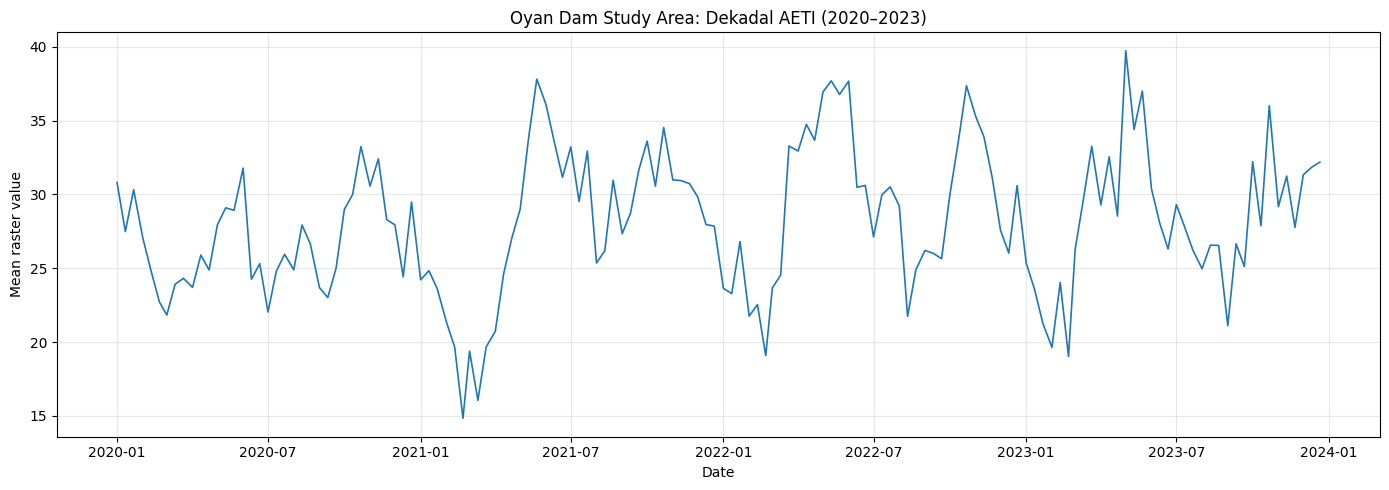

Saved: /content/Oyan_Analysis_Results/Oyan_AETI_Dekadal_TimeSeries.png


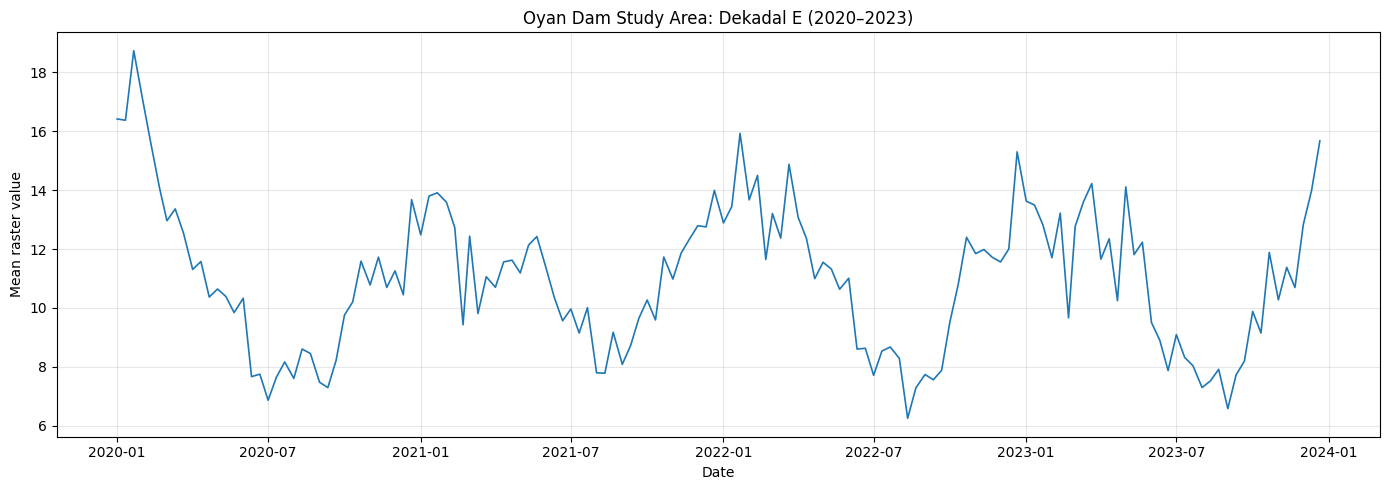

Saved: /content/Oyan_Analysis_Results/Oyan_E_Dekadal_TimeSeries.png


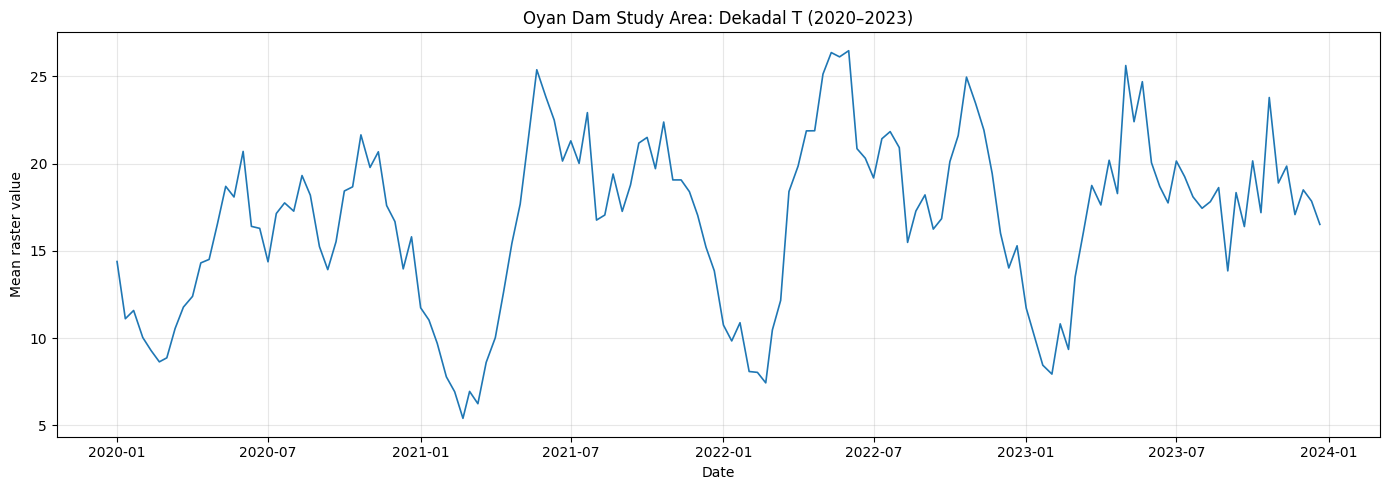

Saved: /content/Oyan_Analysis_Results/Oyan_T_Dekadal_TimeSeries.png


In [12]:

import pandas as pd
import matplotlib.pyplot as plt

csv_path = (
    "/content/Oyan_Analysis_Results/"
    "Oyan_WaPOR_Dekadal_Zonal_Statistics.csv"
)

stats_df = pd.read_csv(csv_path, parse_dates=["Date"])

# Plot each product separately to preserve readable scales
for product in ["AETI", "E", "T"]:
    subset = stats_df[stats_df["Product"] == product].sort_values("Date")

    plt.figure(figsize=(14, 5))
    plt.plot(subset["Date"], subset["Mean"], linewidth=1.2)

    plt.title(
        f"Oyan Dam Study Area: Dekadal {product} (2020–2023)"
    )
    plt.xlabel("Date")
    plt.ylabel("Mean raster value")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    output_file = (
        f"/content/Oyan_Analysis_Results/"
        f"Oyan_{product}_Dekadal_TimeSeries.png"
    )
    plt.savefig(output_file, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", output_file)


<div class="alert alert-success">

⚡ **EXERCISE 1**:  

Write code to find the min, max and mean for the 1st dekad of 2023

Note down the the values (rounded to the nearest integer, no decimals), you will need to enter these in the MOOC quiz.
</div>

In [49]:

import os
import pandas as pd

csv_path = (
    "/content/Oyan_Analysis_Results/"
    "Oyan_WaPOR_Dekadal_Zonal_Statistics.csv"
)

output_folder = "/content/Oyan_Analysis_Results"
os.makedirs(output_folder, exist_ok=True)

# Load the dekadal zonal statistics
stats_df = pd.read_csv(csv_path, parse_dates=["Date"])

# Calculate annual statistics from the 36 dekadal spatial means
annual_summary = (
    stats_df.groupby(["Product", "Year"])["Mean"]
    .agg(
        Minimum="min",
        Maximum="max",
        Mean="mean",
        Std_Dev="std"
    )
    .reset_index()
    .round(3)
)

print("ANNUAL TEMPORAL SUMMARY")
print("Statistics calculated from dekadal spatial means\n")

display(annual_summary)

# Save the results
annual_csv = os.path.join(
    output_folder,
    "Oyan_WaPOR_Annual_Summary.csv"
)

annual_summary.to_csv(annual_csv, index=False)

print("\nSaved annual summary to:", annual_csv)


ANNUAL TEMPORAL SUMMARY
Statistics calculated from dekadal spatial means



,Product,Year,Minimum,Maximum,Mean,Std_Dev
0,AETI,2020,21.833,33.244,26.789,3.050
1,AETI,2021,14.835,37.813,27.791,5.643
2,AETI,2022,19.083,37.694,29.360,5.204
3,AETI,2023,19.022,39.738,28.399,4.690
4,E,2020,6.868,18.731,11.039,3.049
5,E,2021,7.786,13.991,11.023,1.744
6,E,2022,6.255,15.925,11.050,2.492
7,E,2023,6.583,15.671,10.841,2.433
8,T,2020,8.643,21.654,15.454,3.540
9,T,2021,5.405,25.387,16.239,5.660



Saved annual summary to: /content/Oyan_Analysis_Results/Oyan_WaPOR_Annual_Summary.csv


Annual Temporal Summary:
Product  Year  Minimum  Maximum   Mean  Std_Dev
   AETI  2020   21.833   33.244 26.789    3.050
   AETI  2021   14.835   37.813 27.791    5.643
   AETI  2022   19.083   37.694 29.360    5.204
   AETI  2023   19.022   39.738 28.399    4.690
      E  2020    6.868   18.731 11.039    3.049
      E  2021    7.786   13.991 11.023    1.744
      E  2022    6.255   15.925 11.050    2.492
      E  2023    6.583   15.671 10.841    2.433
      T  2020    8.643   21.654 15.454    3.540
      T  2021    5.405   25.387 16.239    5.660
      T  2022    7.438   26.478 18.037    5.513
      T  2023    7.940   25.629 17.278    4.249


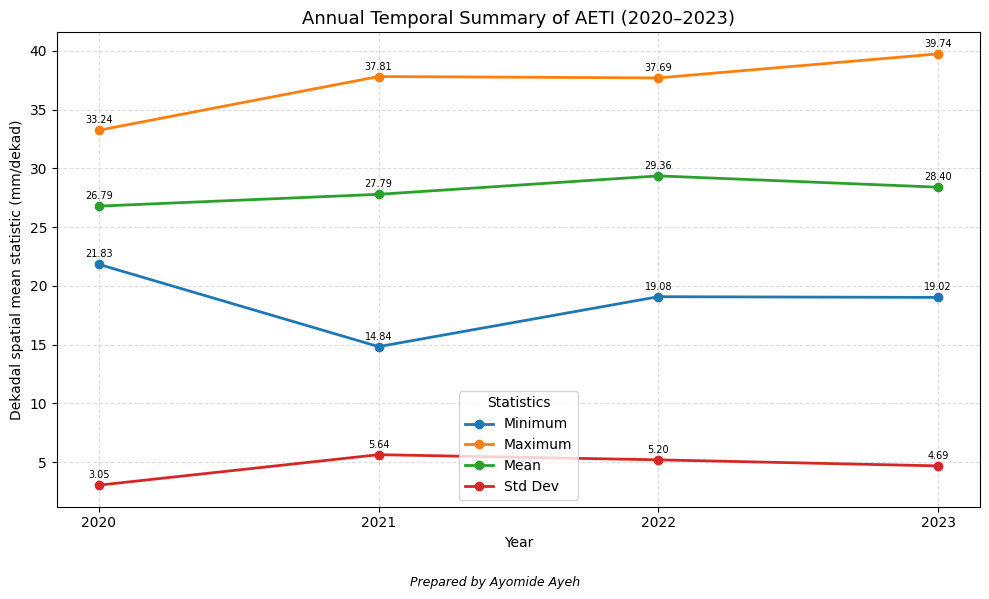

Figure saved: /content/Oyan_Analysis_Results/Annual_Temporal_Summary/Figures/AETI_Annual_Temporal_Summary.png


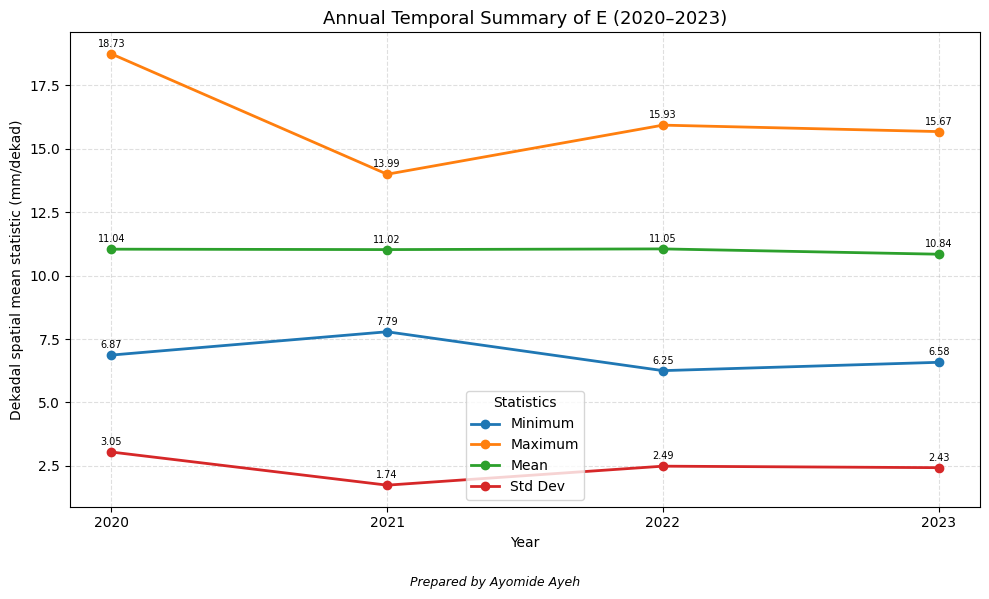

Figure saved: /content/Oyan_Analysis_Results/Annual_Temporal_Summary/Figures/E_Annual_Temporal_Summary.png


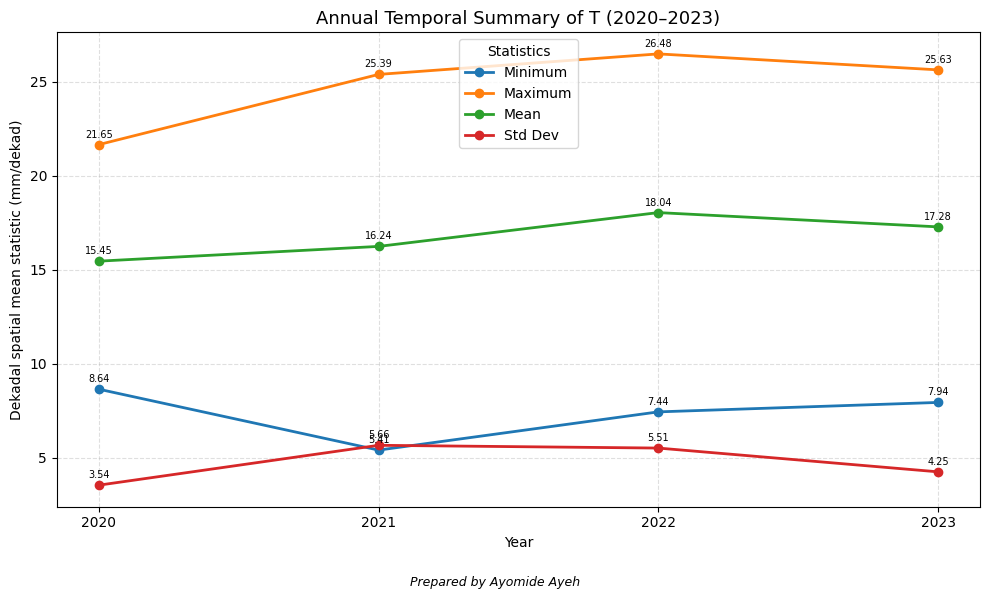

Figure saved: /content/Oyan_Analysis_Results/Annual_Temporal_Summary/Figures/T_Annual_Temporal_Summary.png

Annual temporal summary plots completed.


In [54]:

import os
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. File paths
# --------------------------------------------------
input_csv = (
    "/content/Oyan_Analysis_Results/"
    "Oyan_WaPOR_Annual_Summary.csv"
)

output_dir = (
    "/content/Oyan_Analysis_Results/"
    "Annual_Temporal_Summary/Figures"
)

os.makedirs(output_dir, exist_ok=True)

# --------------------------------------------------
# 2. Load data
# --------------------------------------------------
df = pd.read_csv(input_csv)

print("Annual Temporal Summary:")
print(df.to_string(index=False))

# Ensure numeric columns
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")

statistics = ["Minimum", "Maximum", "Mean", "Std_Dev"]

for column in statistics:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df = df.dropna(subset=["Year"]).sort_values("Year")

# --------------------------------------------------
# 3. Plot each product separately
# --------------------------------------------------
products = ["AETI", "E", "T"]

for product in products:

    product_df = df[df["Product"].str.upper() == product].copy()

    if product_df.empty:
        print(f"No data available for {product}.")
        continue

    fig, ax = plt.subplots(figsize=(10, 6))

    # Plot all four annual statistics
    for stat in statistics:
        ax.plot(
            product_df["Year"],
            product_df[stat],
            marker="o",
            linewidth=2,
            markersize=6,
            label=stat.replace("_", " ")
        )

        # Add labels to each point
        for _, row in product_df.iterrows():
            ax.annotate(
                f'{row[stat]:.2f}',
                (row["Year"], row[stat]),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
                fontsize=7
            )

    ax.set_title(
        f"Annual Temporal Summary of {product} (2020–2023)",
        fontsize=13
    )

    ax.set_xlabel("Year")
    ax.set_ylabel("Dekadal spatial mean statistic (mm/dekad)")
    ax.set_xticks(product_df["Year"].astype(int))
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(title="Statistics")

    # Credit
    fig.text(
        0.5, 0.015,
        "Prepared by Ayomide Ayeh",
        ha="center",
        fontsize=9,
        style="italic"
    )

    plt.tight_layout(rect=[0, 0.05, 1, 1])

    output_file = os.path.join(
        output_dir,
        f"{product}_Annual_Temporal_Summary.png"
    )

    plt.savefig(output_file, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Figure saved: {output_file}")

print("\nAnnual temporal summary plots completed.")


In [55]:

import os
import shutil
from google.colab import files

# Folder containing the figures
figures_dir = (
    "/content/Oyan_Analysis_Results/"
    "Annual_Temporal_Summary/Figures"
)

# Create a ZIP archive
zip_path = "/content/Annual_Temporal_Summary_Figures"

shutil.make_archive(zip_path, "zip", figures_dir)

# Download to your computer
files.download(zip_path + ".zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:

for statistic in ["Minimum", "Maximum", "Mean", "Std_Dev"]:
    print(f"\n{'=' * 55}")
    print(f"ANNUAL {statistic.upper()}")

    comparison = annual_summary.pivot(
        index="Year",
        columns="Product",
        values=statistic
    )

    display(comparison.round(3))



ANNUAL MINIMUM


Product,AETI,E,T
Year,,,
2020,21.833,6.868,8.643
2021,14.835,7.786,5.405
2022,19.083,6.255,7.438
2023,19.022,6.583,7.940



ANNUAL MAXIMUM


Product,AETI,E,T
Year,,,
2020,33.244,18.731,21.654
2021,37.813,13.991,25.387
2022,37.694,15.925,26.478
2023,39.738,15.671,25.629



ANNUAL MEAN


Product,AETI,E,T
Year,,,
2020,26.789,11.039,15.454
2021,27.791,11.023,16.239
2022,29.360,11.050,18.037
2023,28.399,10.841,17.278



ANNUAL STD_DEV


Product,AETI,E,T
Year,,,
2020,3.050,3.049,3.540
2021,5.643,1.744,5.660
2022,5.204,2.492,5.513
2023,4.690,2.433,4.249


In [15]:

import inspect
import rasterio

# 1. Inspect the downloader's conversion function, if still available
try:
    print("Downloader function source:")
    print(inspect.getsource(wapor_map))
except (NameError, OSError, TypeError):
    print("wapor_map source is not available in this session.")

# 2. Inspect metadata embedded in one converted raster
sample_path = (
    "/content/content/output/L1-AETI-D/"
    "Oyan_Study_Area_L1-AETI-D_NONE_dekad_converted_2020-01-01.tif"
)

with rasterio.open(sample_path) as src:
    print("\nRaster tags:")
    print(src.tags())

    print("\nBand tags:")
    print(src.tags(1))


Downloader function source:
wapor_map source is not available in this session.

Raster tags:
{'AREA_OR_POINT': 'Area'}

Band tags:
{'end_date': '2020-01-10', 'long_name': 'Actual EvapoTranspiration and Interception', 'number_of_days': '10', 'original_units': 'mm/day', 'overview': 'NONE', 'start_date': '2020-01-01', 'temporal_resolution': 'Dekad', 'units': 'mm/dekad', 'units_conversion_factor': '10'}


What happens if you do not convert the nans?

### **Step 5 - Seasonal AETI from dekadal AETI**
We will now create one raster file which contains the seasonal AETI value for our area. For this we simply need to loop through the AETI files, and add up the values.   
The glob function allows us to list files in a folder matching a specific pattern.
For example:  
`glob.glob('/content/content/output/L3-AETI-D/*.tif')  `  

will produce a list of all files with the .tif extension contained in the *L3-AETI-D* folder,
while:   
`glob.glob('/content/content/output/L3-AETI-D/*2022-10*.tif')`

will produce a list of all files with the .tif extension which also have the string *202210* in the filename - these will be all of the files from October 2022.


Let's produce a seasonal file for our whole time period (this will add up all the files in the folder):

In [16]:

import os
import pandas as pd

# Input file containing dekadal zonal statistics
csv_path = "/content/Oyan_Analysis_Results/Oyan_WaPOR_Dekadal_Zonal_Statistics.csv"

# Output folder
output_folder = "/content/Oyan_Analysis_Results"

# Load data
stats_df = pd.read_csv(csv_path, parse_dates=["Date"])

# Sum the dekadal spatial means for each product and year
annual_totals = (
    stats_df.groupby(["Product", "Year"])["Mean"]
    .sum()
    .reset_index(name="Annual_Accumulated_Total_mm")
)

annual_totals["Annual_Accumulated_Total_mm"] = (
    annual_totals["Annual_Accumulated_Total_mm"].round(3)
)

# Save results
output_path = os.path.join(
    output_folder,
    "Oyan_WaPOR_Annual_Accumulated_Totals.csv"
)

annual_totals.to_csv(output_path, index=False)

display(annual_totals)

print("Saved annual accumulated totals to:", output_path)


,Product,Year,Annual_Accumulated_Total_mm
0,AETI,2020,964.410
1,AETI,2021,1000.475
2,AETI,2022,1056.945
3,AETI,2023,1022.375
4,E,2020,397.420
5,E,2021,396.837
6,E,2022,397.816
7,E,2023,390.283
8,T,2020,556.356
9,T,2021,584.591


Saved annual accumulated totals to: /content/Oyan_Analysis_Results/Oyan_WaPOR_Annual_Accumulated_Totals.csv


If we inspect the Attributes of ds_sum, you will notice they no longer correspond to our dataset - a consequence of this is the wrong legend on the map produced above - **we do not have 1200mm/dekad of AETI!** (note that if you used d_sum = d_sum + ds instead of d_sum += ds, the attributes will simply have been removed in the result).     
We can **update the Attributes** below.

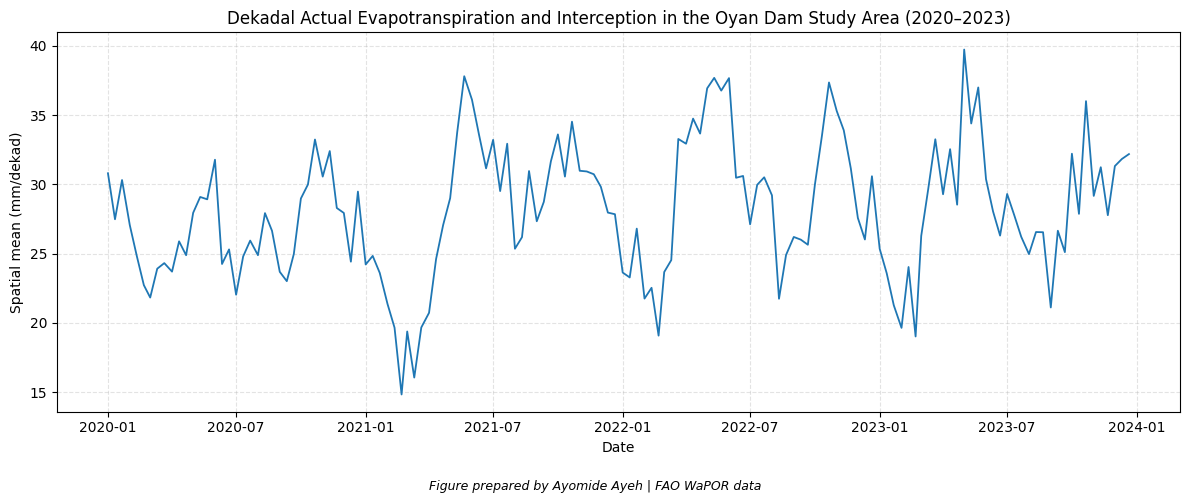

AETI graph saved to: /content/Oyan_Analysis_Results/Oyan_AETI_Dekadal_TimeSeries.png


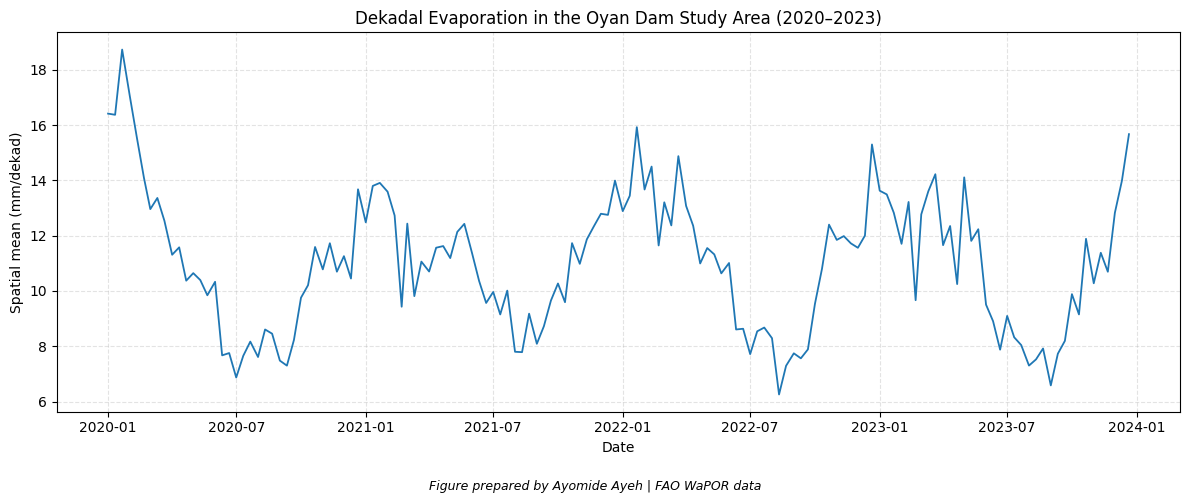

E graph saved to: /content/Oyan_Analysis_Results/Oyan_E_Dekadal_TimeSeries.png


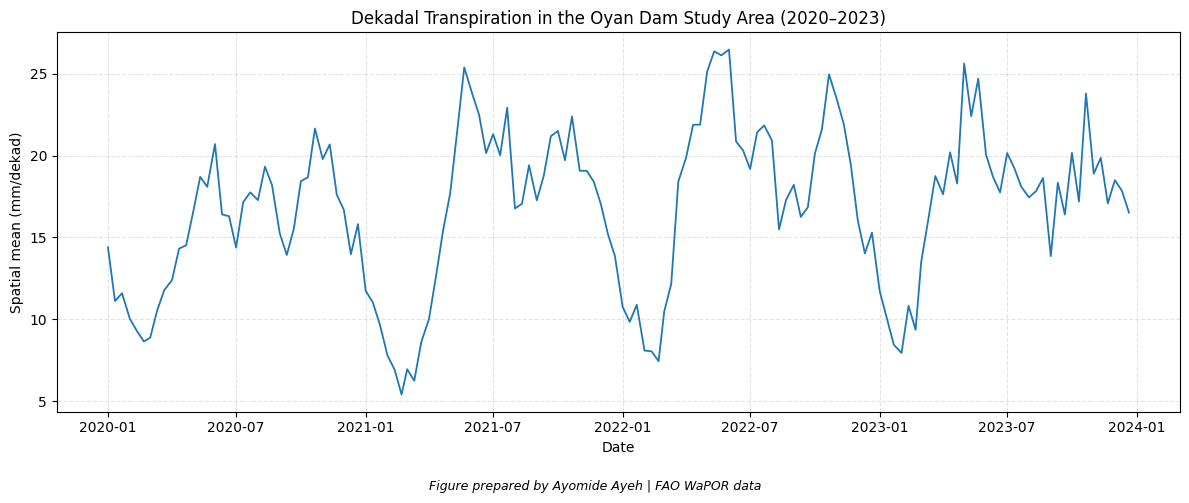

T graph saved to: /content/Oyan_Analysis_Results/Oyan_T_Dekadal_TimeSeries.png


In [18]:

import os
import pandas as pd
import matplotlib.pyplot as plt

# Load dekadal zonal statistics
csv_path = (
    "/content/Oyan_Analysis_Results/"
    "Oyan_WaPOR_Dekadal_Zonal_Statistics.csv"
)
output_folder = "/content/Oyan_Analysis_Results"

stats_df = pd.read_csv(csv_path, parse_dates=["Date"])

# Product names and graph titles
products = {
    "AETI": "Actual Evapotranspiration and Interception",
    "E": "Evaporation",
    "T": "Transpiration"
}

for product, title in products.items():

    subset = stats_df[stats_df["Product"] == product].sort_values("Date")

    plt.figure(figsize=(12, 5))

    plt.plot(
        subset["Date"],
        subset["Mean"],
        linewidth=1.3
    )

    plt.title(f"Dekadal {title} in the Oyan Dam Study Area (2020–2023)")
    plt.xlabel("Date")
    plt.ylabel("Spatial mean (mm/dekad)")
    plt.grid(True, linestyle="--", alpha=0.35)

    plt.figtext(
        0.5, 0.01,
        f"Figure prepared by Ayomide Ayeh | FAO WaPOR data",
        ha="center",
        fontsize=9,
        style="italic"
    )

    plt.tight_layout(rect=[0, 0.05, 1, 1])

    figure_path = os.path.join(
        output_folder,
        f"Oyan_{product}_Dekadal_TimeSeries.png"
    )

    plt.savefig(figure_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print(f"{product} graph saved to: {figure_path}")


In [58]:

import os
import zipfile
from google.colab import files

source_dir = "/content/Oyan_Analysis_Results"

graph_files = [
    "Oyan_AETI_Dekadal_TimeSeries.png",
    "Oyan_E_Dekadal_TimeSeries.png",
    "Oyan_T_Dekadal_TimeSeries.png"
]

zip_path = "/content/Oyan_Dekadal_TimeSeries_Graphs.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in graph_files:
        filepath = os.path.join(source_dir, filename)

        if os.path.exists(filepath):
            zipf.write(filepath, arcname=filename)
            print(f"Added: {filename}")
        else:
            print(f"File not found: {filepath}")

files.download(zip_path)


Added: Oyan_AETI_Dekadal_TimeSeries.png
Added: Oyan_E_Dekadal_TimeSeries.png
Added: Oyan_T_Dekadal_TimeSeries.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:

import os
import pandas as pd
import matplotlib.pyplot as plt

# Load dekadal statistics
csv_path = (
    "/content/Oyan_Analysis_Results/"
    "Oyan_WaPOR_Dekadal_Zonal_Statistics.csv"
)
output_folder = "/content/Oyan_Analysis_Results"

stats_df = pd.read_csv(csv_path, parse_dates=["Date"])

# Assign each dekad to its calendar month
stats_df["Month"] = stats_df["Date"].dt.month
stats_df["Year"] = stats_df["Date"].dt.year

# Sum dekadal spatial means within each month
monthly_df = (
    stats_df.groupby(["Product", "Year", "Month"])["Mean"]
    .sum()
    .reset_index(name="Monthly_Accumulated_Total_mm")
)

# Save monthly results
monthly_csv = os.path.join(
    output_folder,
    "Oyan_WaPOR_Monthly_Accumulated_Totals.csv"
)
monthly_df.to_csv(monthly_csv, index=False)

print("Monthly results saved to:", monthly_csv)
display(monthly_df.head(12))


Monthly results saved to: /content/Oyan_Analysis_Results/Oyan_WaPOR_Monthly_Accumulated_Totals.csv


,Product,Year,Month,Monthly_Accumulated_Total_mm
0,AETI,2020,1,88.613317
1,AETI,2020,2,74.621732
2,AETI,2020,3,70.069526
3,AETI,2020,4,74.487745
4,AETI,2020,5,85.971977
5,AETI,2020,6,81.350490
6,AETI,2020,7,72.781944
7,AETI,2020,8,79.470997
8,AETI,2020,9,71.693627
9,AETI,2020,10,92.223938


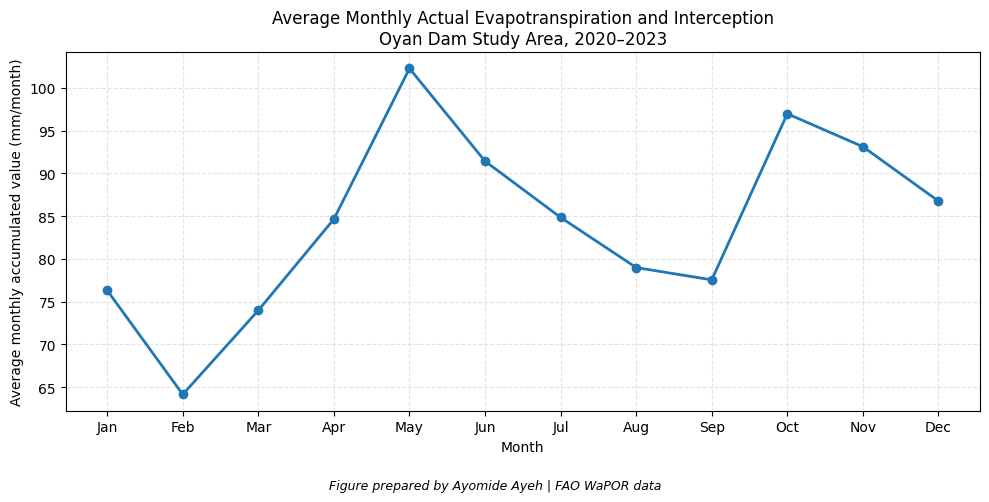

Saved: /content/Oyan_Analysis_Results/Oyan_AETI_Average_Monthly_Pattern.png


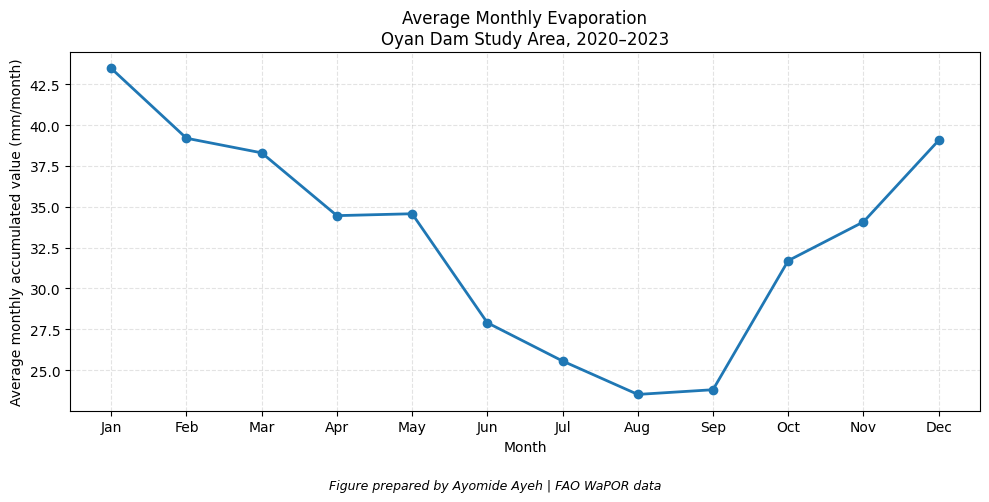

Saved: /content/Oyan_Analysis_Results/Oyan_E_Average_Monthly_Pattern.png


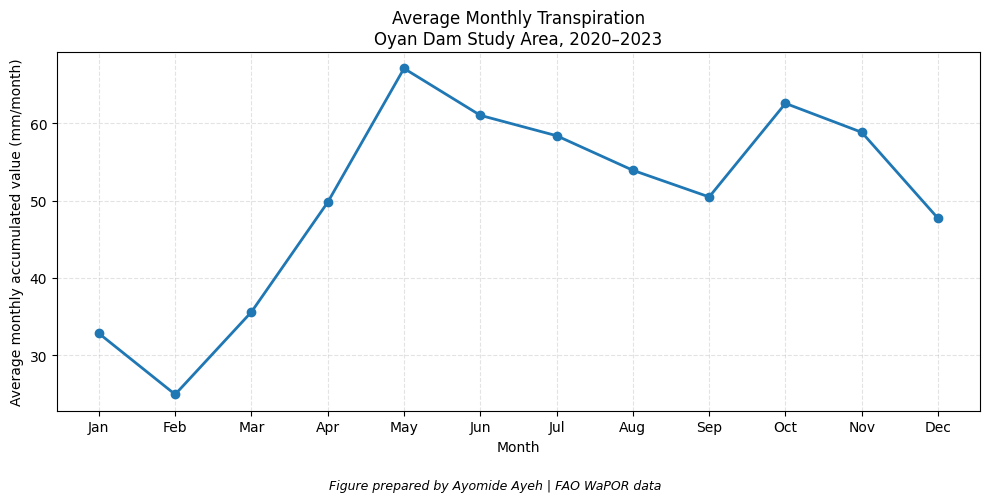

Saved: /content/Oyan_Analysis_Results/Oyan_T_Average_Monthly_Pattern.png


In [20]:

# Average monthly totals across 2020–2023
monthly_climatology = (
    monthly_df.groupby(["Product", "Month"])
    ["Monthly_Accumulated_Total_mm"]
    .mean()
    .reset_index()
)

product_titles = {
    "AETI": "Actual Evapotranspiration and Interception",
    "E": "Evaporation",
    "T": "Transpiration"
}

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

for product, title in product_titles.items():

    subset = (
        monthly_climatology[
            monthly_climatology["Product"] == product
        ].sort_values("Month")
    )

    plt.figure(figsize=(10, 5))

    plt.plot(
        subset["Month"],
        subset["Monthly_Accumulated_Total_mm"],
        marker="o",
        linewidth=2
    )

    plt.xticks(range(1, 13), month_names)
    plt.xlabel("Month")
    plt.ylabel("Average monthly accumulated value (mm/month)")
    plt.title(
        f"Average Monthly {title}\n"
        "Oyan Dam Study Area, 2020–2023"
    )
    plt.grid(True, linestyle="--", alpha=0.35)

    plt.figtext(
        0.5, 0.01,
        "Figure prepared by Ayomide Ayeh | FAO WaPOR data",
        ha="center",
        fontsize=9,
        style="italic"
    )

    plt.tight_layout(rect=[0, 0.05, 1, 1])

    figure_path = os.path.join(
        output_folder,
        f"Oyan_{product}_Average_Monthly_Pattern.png"
    )

    plt.savefig(figure_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", figure_path)


In [21]:

import os
import pandas as pd

output_folder = "/content/Oyan_Analysis_Results"

monthly_csv = os.path.join(
    output_folder,
    "Oyan_WaPOR_Monthly_Accumulated_Totals.csv"
)

monthly_df = pd.read_csv(monthly_csv)

month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

# Average each month's accumulated value across the four years
monthly_climatology = (
    monthly_df.groupby(["Product", "Month"])
    ["Monthly_Accumulated_Total_mm"]
    .mean()
    .reset_index()
)

monthly_climatology["Month_Name"] = (
    monthly_climatology["Month"].map(month_names)
)

# Find highest and lowest monthly averages for each product
results = []

for product, group in monthly_climatology.groupby("Product"):
    highest = group.loc[group["Monthly_Accumulated_Total_mm"].idxmax()]
    lowest = group.loc[group["Monthly_Accumulated_Total_mm"].idxmin()]

    results.append({
        "Product": product,
        "Highest_Month": highest["Month_Name"],
        "Highest_Average_mm": round(
            highest["Monthly_Accumulated_Total_mm"], 2
        ),
        "Lowest_Month": lowest["Month_Name"],
        "Lowest_Average_mm": round(
            lowest["Monthly_Accumulated_Total_mm"], 2
        )
    })

extremes_df = pd.DataFrame(results)
display(extremes_df)

extremes_df.to_csv(
    os.path.join(output_folder, "Oyan_Monthly_Pattern_Extremes.csv"),
    index=False
)

print("Monthly pattern results saved.")


,Product,Highest_Month,Highest_Average_mm,Lowest_Month,Lowest_Average_mm
0,AETI,May,102.28,February,64.14
1,E,January,43.48,August,23.50
2,T,May,67.07,February,24.94


Monthly pattern results saved.


In [22]:

import os
import glob
import re

base_path = "/content/content/output"

products = {
    "AETI": os.path.join(base_path, "L1-AETI-D"),
    "E": os.path.join(base_path, "L1-E-D"),
    "T": os.path.join(base_path, "L1-T-D")
}

for product, folder in products.items():
    files = sorted(glob.glob(os.path.join(folder, "*.tif")))

    files_2022 = [
        f for f in files
        if (match := re.search(r"(\d{4}-\d{2}-\d{2})\.tif$", os.path.basename(f)))
        and match.group(1).startswith("2022-")
    ]

    print(f"{product}: {len(files_2022)} rasters for 2022")
    if files_2022:
        print("First:", os.path.basename(files_2022[0]))
        print("Last: ", os.path.basename(files_2022[-1]))
    else:
        print("No 2022 rasters found. Check the folder path.")
    print()


AETI: 36 rasters for 2022
First: Oyan_Study_Area_L1-AETI-D_NONE_dekad_converted_2022-01-01.tif
Last:  Oyan_Study_Area_L1-AETI-D_NONE_dekad_converted_2022-12-21.tif

E: 36 rasters for 2022
First: Oyan_Study_Area_L1-E-D_NONE_dekad_converted_2022-01-01.tif
Last:  Oyan_Study_Area_L1-E-D_NONE_dekad_converted_2022-12-21.tif

T: 36 rasters for 2022
First: Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2022-01-01.tif
Last:  Oyan_Study_Area_L1-T-D_NONE_dekad_converted_2022-12-21.tif



In [23]:

import os
import glob
import re
import numpy as np
import rasterio

base_path = "/content/content/output"
output_folder = "/content/Oyan_Analysis_Results/Spatial_Maps_2022"
os.makedirs(output_folder, exist_ok=True)

products = {
    "AETI": os.path.join(base_path, "L1-AETI-D"),
    "E": os.path.join(base_path, "L1-E-D"),
    "T": os.path.join(base_path, "L1-T-D")
}

for product, folder in products.items():

    all_files = sorted(glob.glob(os.path.join(folder, "*.tif")))

    raster_files = [
        f for f in all_files
        if (match := re.search(
            r"(\d{4}-\d{2}-\d{2})\.tif$",
            os.path.basename(f)
        ))
        and match.group(1).startswith("2022-")
    ]

    if len(raster_files) != 36:
        raise ValueError(
            f"{product}: expected 36 rasters for 2022, "
            f"but found {len(raster_files)}"
        )

    pixel_arrays = []
    profile = None

    for raster_path in raster_files:
        with rasterio.open(raster_path) as src:
            if profile is None:
                profile = src.profile.copy()
                reference_shape = (src.height, src.width)
                reference_transform = src.transform
                reference_crs = src.crs

            if (
                (src.height, src.width) != reference_shape
                or src.transform != reference_transform
                or src.crs != reference_crs
            ):
                raise ValueError(
                    f"Grid mismatch in {raster_path}"
                )

            data = src.read(1).astype("float32")
            valid = np.isfinite(data)

            if src.nodata is not None:
                valid &= data != src.nodata

            # Mask invalid cells before calculating the mean
            data[~valid] = np.nan
            pixel_arrays.append(data)

    stack = np.stack(pixel_arrays, axis=0)
    annual_mean = np.nanmean(stack, axis=0).astype("float32")

    # Preserve invalid pixels as NoData
    annual_mean[~np.isfinite(annual_mean)] = -9999.0

    profile.update(
        driver="GTiff",
        dtype="float32",
        count=1,
        nodata=-9999.0,
        compress="lzw"
    )

    output_path = os.path.join(
        output_folder,
        f"Oyan_{product}_2022_Mean_Dekadal.tif"
    )

    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(annual_mean, 1)
        dst.update_tags(
            product=product,
            year="2022",
            statistic="Pixel-wise mean of 36 dekadal rasters",
            units="mm/dekad",
            prepared_by="Ayomide Ayeh"
        )

    valid_pixels = annual_mean[annual_mean != -9999.0]

    print(f"\n{product} completed")
    print("Saved:", output_path)
    print("Valid pixels:", len(valid_pixels))
    print("Minimum:", round(float(valid_pixels.min()), 3))
    print("Maximum:", round(float(valid_pixels.max()), 3))
    print("Mean:", round(float(valid_pixels.mean()), 3))

print("\nAll three 2022 spatial mean rasters have been created.")


/tmp/ipykernel_3045/3706133590.py:67: RuntimeWarning: Mean of empty slice
  annual_mean = np.nanmean(stack, axis=0).astype("float32")



AETI completed
Saved: /content/Oyan_Analysis_Results/Spatial_Maps_2022/Oyan_AETI_2022_Mean_Dekadal.tif
Valid pixels: 1326
Minimum: 16.597
Maximum: 61.469
Mean: 29.126

E completed
Saved: /content/Oyan_Analysis_Results/Spatial_Maps_2022/Oyan_E_2022_Mean_Dekadal.tif
Valid pixels: 1326
Minimum: 2.203
Maximum: 41.594
Mean: 10.514

T completed
Saved: /content/Oyan_Analysis_Results/Spatial_Maps_2022/Oyan_T_2022_Mean_Dekadal.tif
Valid pixels: 1326
Minimum: 1.95
Maximum: 26.006
Mean: 18.331

All three 2022 spatial mean rasters have been created.


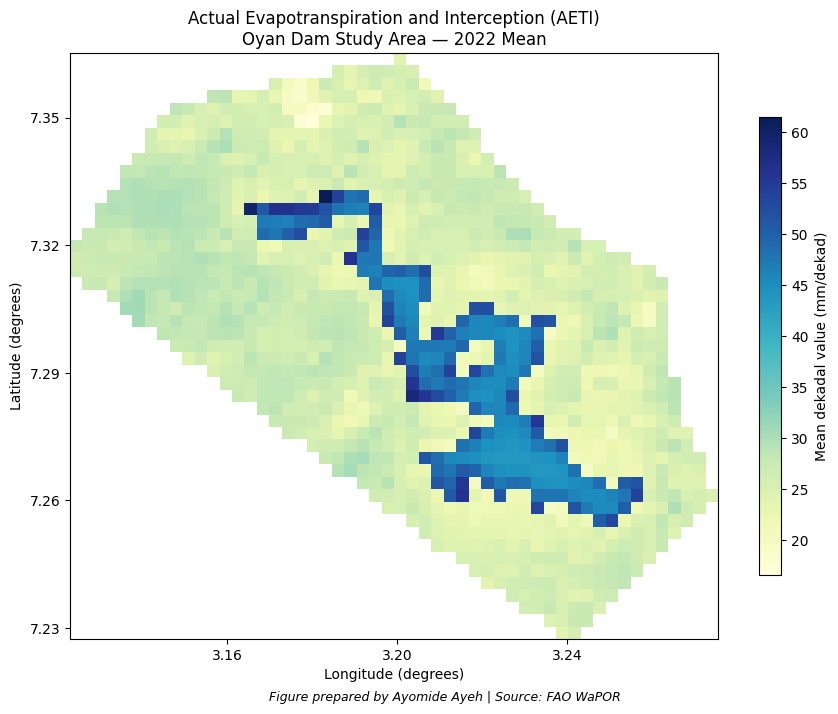


AETI
Valid pixels: 1326
Minimum: 16.597 mm/dekad
Maximum: 61.469 mm/dekad
Mean: 29.126 mm/dekad
Map saved: /content/Oyan_Analysis_Results/Spatial_Maps_2022/Oyan_AETI_2022_Spatial_Map.png


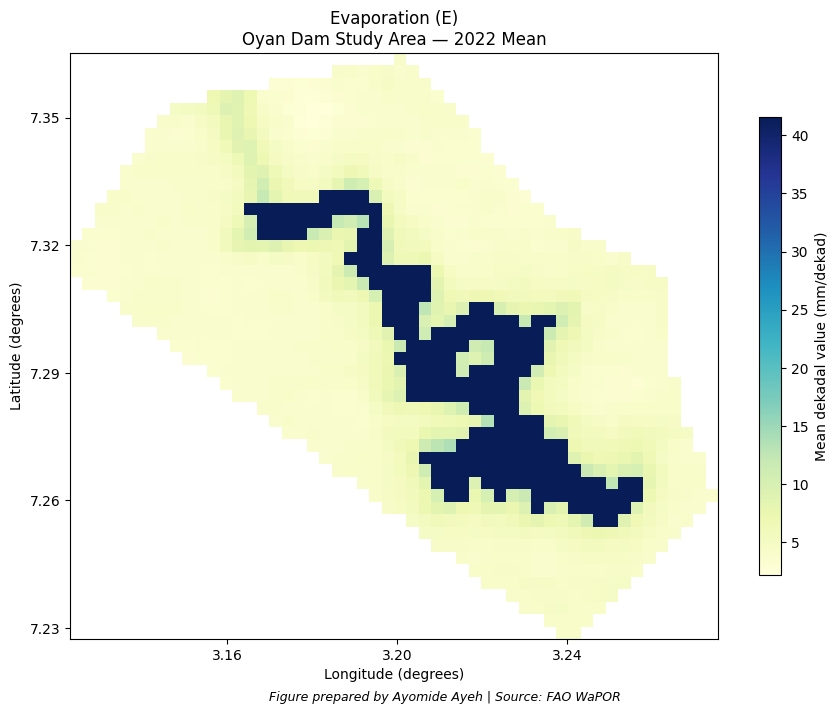


E
Valid pixels: 1326
Minimum: 2.203 mm/dekad
Maximum: 41.594 mm/dekad
Mean: 10.514 mm/dekad
Map saved: /content/Oyan_Analysis_Results/Spatial_Maps_2022/Oyan_E_2022_Spatial_Map.png


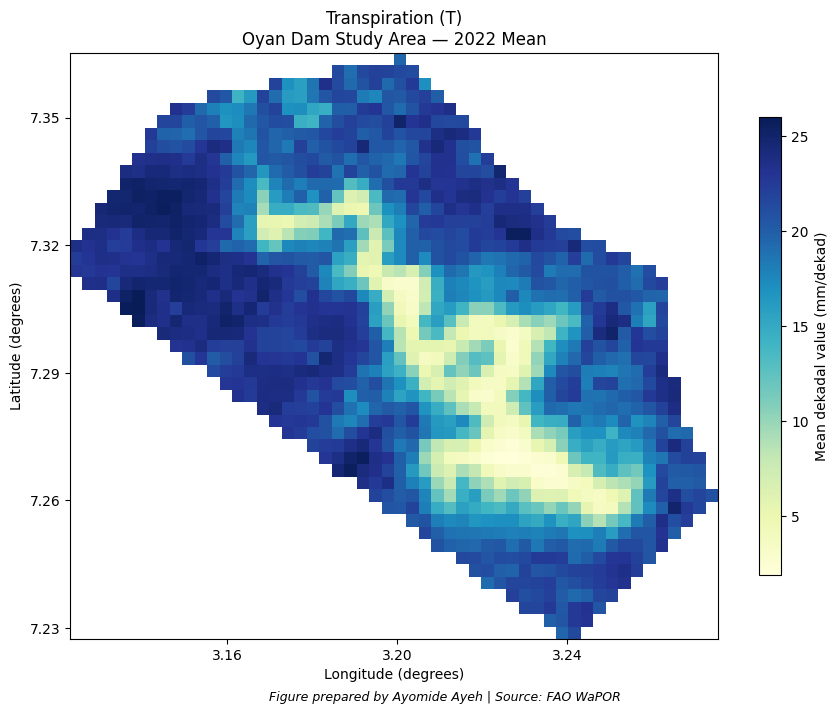


T
Valid pixels: 1326
Minimum: 1.95 mm/dekad
Maximum: 26.006 mm/dekad
Mean: 18.331 mm/dekad
Map saved: /content/Oyan_Analysis_Results/Spatial_Maps_2022/Oyan_T_2022_Spatial_Map.png

All three spatial maps have been generated.


In [24]:

import os
import glob
import re
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

base_path = "/content/content/output"
output_folder = "/content/Oyan_Analysis_Results/Spatial_Maps_2022"
os.makedirs(output_folder, exist_ok=True)

products = {
    "AETI": {
        "folder": os.path.join(base_path, "L1-AETI-D"),
        "title": "Actual Evapotranspiration and Interception (AETI)"
    },
    "E": {
        "folder": os.path.join(base_path, "L1-E-D"),
        "title": "Evaporation (E)"
    },
    "T": {
        "folder": os.path.join(base_path, "L1-T-D"),
        "title": "Transpiration (T)"
    }
}

for product, info in products.items():
    files = sorted(glob.glob(os.path.join(info["folder"], "*.tif")))
    files = [
        f for f in files
        if (match := re.search(
            r"(\d{4}-\d{2}-\d{2})\.tif$",
            os.path.basename(f)
        ))
        and match.group(1).startswith("2022-")
    ]

    if len(files) != 36:
        raise ValueError(f"{product}: expected 36 rasters, found {len(files)}")

    total = None
    count = None
    reference_profile = None
    reference_transform = None
    reference_crs = None

    for path in files:
        with rasterio.open(path) as src:
            if reference_profile is None:
                reference_profile = src.profile.copy()
                reference_transform = src.transform
                reference_crs = src.crs
                shape = (src.height, src.width)
                total = np.zeros(shape, dtype=np.float64)
                count = np.zeros(shape, dtype=np.uint16)

            if (
                (src.height, src.width) != shape
                or src.transform != reference_transform
                or src.crs != reference_crs
            ):
                raise ValueError(f"Grid mismatch: {path}")

            data = src.read(1).astype(np.float64)
            valid = np.isfinite(data)

            if src.nodata is not None:
                valid &= data != src.nodata

            # Exclude common WaPOR fill values if present
            valid &= data != 255
            valid &= data != -9999

            total[valid] += data[valid]
            count[valid] += 1

    # Calculate mean only where at least one valid observation exists
    annual_mean = np.full(shape, -9999, dtype=np.float32)
    has_data = count > 0
    annual_mean[has_data] = (
        total[has_data] / count[has_data]
    ).astype(np.float32)

    # Clean the inherited GeoTIFF profile to avoid block-size warnings
    profile = reference_profile.copy()
    for key in ["blockxsize", "blockysize", "photometric"]:
        profile.pop(key, None)

    profile.update(
        driver="GTiff",
        dtype="float32",
        count=1,
        nodata=-9999.0,
        compress="lzw",
        tiled=False
    )

    tif_path = os.path.join(
        output_folder, f"Oyan_{product}_2022_Mean_Dekadal.tif"
    )

    with rasterio.open(tif_path, "w", **profile) as dst:
        dst.write(annual_mean, 1)
        dst.update_tags(
            product=product,
            year="2022",
            statistic="Mean of valid dekadal values",
            units="mm/dekad",
            prepared_by="Ayomide Ayeh"
        )

    # Prepare a masked array for plotting
    display_data = np.ma.masked_where(
        annual_mean == -9999, annual_mean
    )

    valid_values = annual_mean[has_data]

    fig, ax = plt.subplots(figsize=(9, 7))

    image = ax.imshow(
        display_data,
        extent=[
            reference_transform.c,
            reference_transform.c + reference_transform.a * shape[1],
            reference_transform.f + reference_transform.e * shape[0],
            reference_transform.f
        ],
        origin="upper",
        cmap="YlGnBu"
    )

    colorbar = fig.colorbar(image, ax=ax, shrink=0.78)
    colorbar.set_label("Mean dekadal value (mm/dekad)")

    ax.set_title(
        f'{info["title"]}\n'
        "Oyan Dam Study Area — 2022 Mean"
    )
    ax.set_xlabel("Longitude (degrees)")
    ax.set_ylabel("Latitude (degrees)")
    ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.yaxis.set_major_locator(MaxNLocator(5))

    fig.text(
        0.5, 0.015,
        "Figure prepared by Ayomide Ayeh | Source: FAO WaPOR",
        ha="center",
        fontsize=9,
        style="italic"
    )

    fig.tight_layout(rect=[0, 0.045, 1, 1])

    png_path = os.path.join(
        output_folder, f"Oyan_{product}_2022_Spatial_Map.png"
    )
    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"\n{product}")
    print("Valid pixels:", int(has_data.sum()))
    print("Minimum:", round(float(valid_values.min()), 3), "mm/dekad")
    print("Maximum:", round(float(valid_values.max()), 3), "mm/dekad")
    print("Mean:", round(float(valid_values.mean()), 3), "mm/dekad")
    print("Map saved:", png_path)

print("\nAll three spatial maps have been generated.")


In [27]:

import os
import glob
import numpy as np
import pandas as pd
import rasterio

# Input and output folders
base_folder = "/content/content/output"
output_folder = "/content/Oyan_Analysis_Results"
seasonal_folder = os.path.join(
    output_folder, "Seasonal_Accumulated_Rasters"
)
os.makedirs(seasonal_folder, exist_ok=True)

product_folders = {
    "AETI": os.path.join(base_folder, "L1-AETI-D"),
    "E": os.path.join(base_folder, "L1-E-D"),
    "T": os.path.join(base_folder, "L1-T-D"),
}

seasons = {
    "Season_1": [1, 2, 3],
    "Season_2": [4, 5, 6],
    "Season_3": [7, 8, 9],
    "Season_4": [10, 11, 12],
}

years = [2020, 2021, 2022, 2023]
summary_records = []

for product, folder in product_folders.items():
    files = sorted(glob.glob(os.path.join(folder, "*.tif")))

    if not files:
        print(f"WARNING: No rasters found for {product}: {folder}")
        continue

    dated_files = []
    for path in files:
        date_text = os.path.basename(path).rsplit("_", 1)[-1]
        date_text = date_text.replace(".tif", "")

        try:
            date = pd.to_datetime(date_text, format="%Y-%m-%d")
            dated_files.append((date, path))
        except ValueError:
            print(f"Skipping unrecognised filename: {path}")

    for season, months in seasons.items():
        for year in years:
            selected = sorted([
                (date, path)
                for date, path in dated_files
                if date.year == year and date.month in months
            ])

            if len(selected) != 9:
                print(
                    f"WARNING: {product} {season} {year}: "
                    f"expected 9 dekads, found {len(selected)}. Skipped."
                )
                continue

            arrays = []
            profile = None
            reference_shape = None

            for date, path in selected:
                with rasterio.open(path) as src:
                    arr = src.read(1).astype("float32")
                    invalid = ~np.isfinite(arr)

                    if src.nodata is not None:
                        invalid |= np.isclose(arr, src.nodata)

                    # NoData conventions for these WaPOR products
                    if product in ("E", "T"):
                        invalid |= np.isclose(arr, 255)
                    invalid |= np.isclose(arr, -9999)

                    arr[invalid] = np.nan

                    if profile is None:
                        profile = src.profile.copy()
                        reference_shape = arr.shape
                    elif arr.shape != reference_shape:
                        raise ValueError(
                            f"Raster dimensions differ: {path}"
                        )

                    arrays.append(arr)

            stack = np.stack(arrays, axis=0)
            valid_count = np.isfinite(stack).sum(axis=0)

            # Accumulated water depth for the three-month period.
            seasonal_sum = np.nansum(stack, axis=0)

            # Avoid reporting partial-season totals where any dekad
            # is missing at a pixel.
            seasonal_sum[valid_count != 9] = np.nan

            valid = seasonal_sum[np.isfinite(seasonal_sum)]

            output_path = os.path.join(
                seasonal_folder,
                f"Oyan_{product}_{season}_{year}_Sum.tif"
            )

            profile.update(
                dtype="float32",
                count=1,
                nodata=-9999.0,
                compress="lzw",
                tiled=False
            )
            profile.pop("blockxsize", None)
            profile.pop("blockysize", None)
            profile.pop("photometric", None)

            output_array = np.where(
                np.isfinite(seasonal_sum),
                seasonal_sum,
                -9999.0
            ).astype("float32")

            with rasterio.open(output_path, "w", **profile) as dst:
                dst.write(output_array, 1)
                dst.update_tags(
                    product=product,
                    season=season,
                    year=str(year),
                    units="mm/season",
                    aggregation="sum of 9 dekadal rasters",
                    source="FAO WaPOR",
                    prepared_by="Ayomide Ayeh"
                )

            summary_records.append({
                "Product": product,
                "Season": season,
                "Year": year,
                "Dekads_Used": len(selected),
                "Valid_Pixels": int(valid.size),
                "Mean_mm_season": float(np.mean(valid)) if valid.size else np.nan,
                "Minimum_mm_season": float(np.min(valid)) if valid.size else np.nan,
                "Maximum_mm_season": float(np.max(valid)) if valid.size else np.nan,
                "Std_Dev_mm_season": float(np.std(valid)) if valid.size else np.nan,
                "Raster": output_path
            })

            print(f"Saved {product} {season} {year}: 9 dekads")

summary = pd.DataFrame(summary_records)
csv_path = os.path.join(
    output_folder,
    "Oyan_WaPOR_Seasonal_Accumulated_Summary.csv"
)
summary.to_csv(csv_path, index=False)

print("\nSeasonal aggregation finished.")
print("Seasonal rasters created:", len(summary))
print("Summary CSV:", csv_path)

if not summary.empty:
    display(summary.head(12))


Saved AETI Season_1 2020: 9 dekads
Saved AETI Season_1 2021: 9 dekads
Saved AETI Season_1 2022: 9 dekads
Saved AETI Season_1 2023: 9 dekads
Saved AETI Season_2 2020: 9 dekads
Saved AETI Season_2 2021: 9 dekads
Saved AETI Season_2 2022: 9 dekads
Saved AETI Season_2 2023: 9 dekads
Saved AETI Season_3 2020: 9 dekads
Saved AETI Season_3 2021: 9 dekads
Saved AETI Season_3 2022: 9 dekads
Saved AETI Season_3 2023: 9 dekads
Saved AETI Season_4 2020: 9 dekads
Saved AETI Season_4 2021: 9 dekads
Saved AETI Season_4 2022: 9 dekads
Saved AETI Season_4 2023: 9 dekads
Saved E Season_1 2020: 9 dekads
Saved E Season_1 2021: 9 dekads
Saved E Season_1 2022: 9 dekads
Saved E Season_1 2023: 9 dekads
Saved E Season_2 2020: 9 dekads
Saved E Season_2 2021: 9 dekads
Saved E Season_2 2022: 9 dekads
Saved E Season_2 2023: 9 dekads
Saved E Season_3 2020: 9 dekads
Saved E Season_3 2021: 9 dekads
Saved E Season_3 2022: 9 dekads
Saved E Season_3 2023: 9 dekads
Saved E Season_4 2020: 9 dekads
Saved E Season_4 2021: 9

,Product,Season,Year,Dekads_Used,Valid_Pixels,Mean_mm_season,Minimum_mm_season,Maximum_mm_season,Std_Dev_mm_season,Raster
0,AETI,Season_1,2020,9,1326,229.151062,93.599998,605.000000,131.241791,/content/Oyan_Analysis_Results/Seasonal_Accumu...
1,AETI,Season_1,2021,9,1326,179.364029,34.299999,528.199951,116.360001,/content/Oyan_Analysis_Results/Seasonal_Accumu...
2,AETI,Season_1,2022,9,1326,214.715149,93.200005,548.000000,110.232086,/content/Oyan_Analysis_Results/Seasonal_Accumu...
3,AETI,Season_1,2023,9,1326,217.237564,50.100002,586.900024,118.301254,/content/Oyan_Analysis_Results/Seasonal_Accumu...
4,AETI,Season_2,2020,9,1326,238.651276,4.000000,607.200012,124.860199,/content/Oyan_Analysis_Results/Seasonal_Accumu...
5,AETI,Season_2,2021,9,1326,268.800446,30.299999,661.400024,123.373177,/content/Oyan_Analysis_Results/Seasonal_Accumu...
6,AETI,Season_2,2022,9,1326,308.418549,27.100000,631.599976,96.828072,/content/Oyan_Analysis_Results/Seasonal_Accumu...
7,AETI,Season_2,2023,9,1326,281.677826,0.000000,605.799988,112.596672,/content/Oyan_Analysis_Results/Seasonal_Accumu...
8,AETI,Season_3,2020,9,1326,223.717499,2.000000,415.799988,51.809788,/content/Oyan_Analysis_Results/Seasonal_Accumu...
9,AETI,Season_3,2021,9,1326,265.174438,96.399994,486.399994,55.336018,/content/Oyan_Analysis_Results/Seasonal_Accumu...


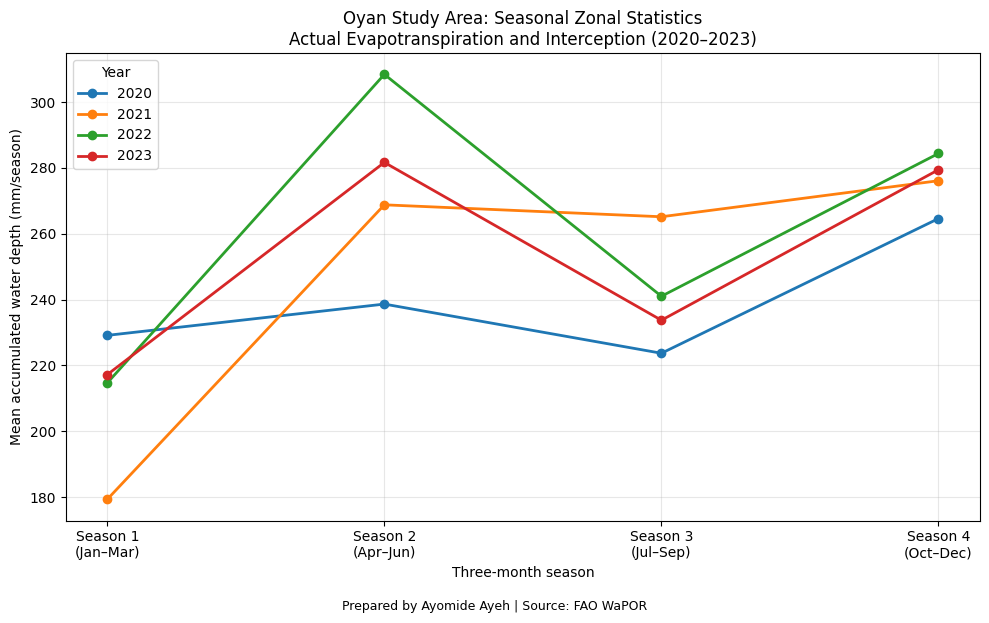

Saved: /content/Oyan_Analysis_Results/Seasonal_Zonal_Statistics_Figures/Oyan_AETI_Seasonal_Zonal_Statistics.png


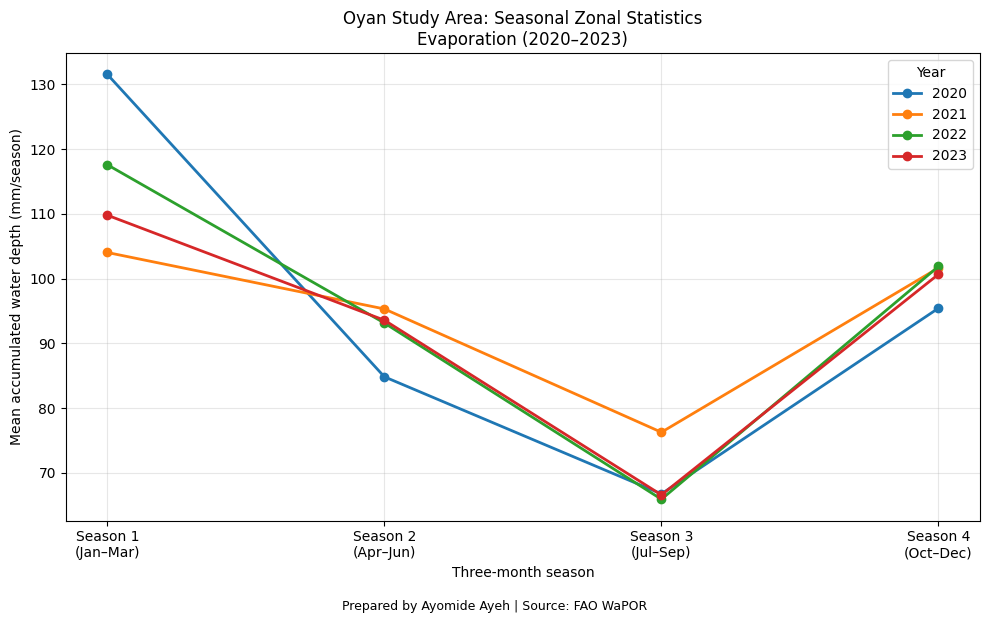

Saved: /content/Oyan_Analysis_Results/Seasonal_Zonal_Statistics_Figures/Oyan_E_Seasonal_Zonal_Statistics.png


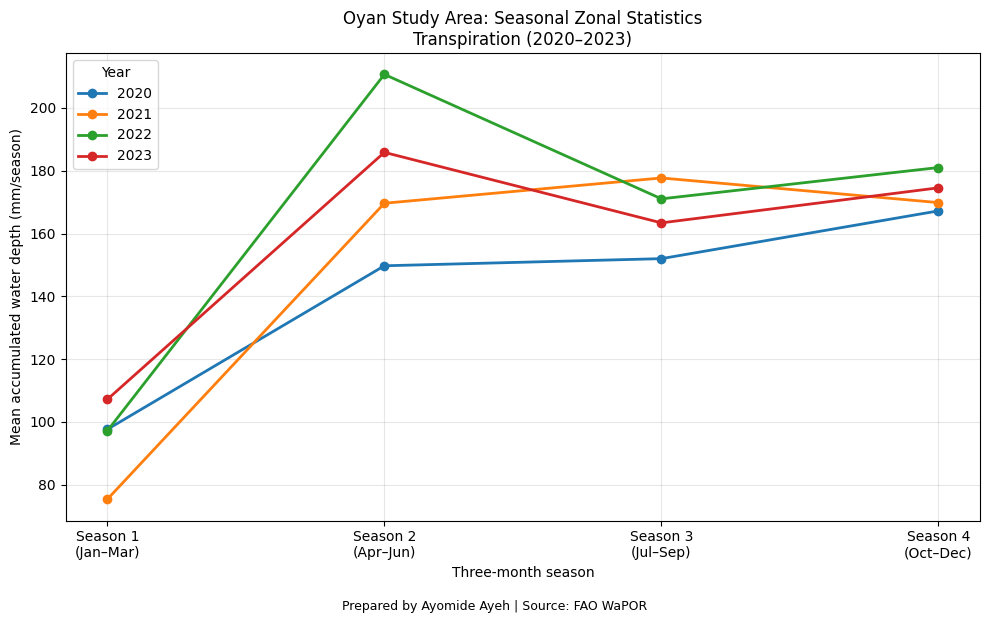

Saved: /content/Oyan_Analysis_Results/Seasonal_Zonal_Statistics_Figures/Oyan_T_Seasonal_Zonal_Statistics.png

Seasonal comparison table:


Product          AETI       E       T
Season   Year                        
Season_1 2020  229.15  131.54   97.61
         2021  179.36  104.03   75.33
         2022  214.72  117.58   97.13
         2023  217.24  109.79  107.15
Season_2 2020  238.65   84.83  149.72
         2021  268.80   95.31  169.65
         2022  308.42   93.14  210.70
         2023  281.68   93.57  185.85
Season_3 2020  223.72   66.74  152.00
         2021  265.17   76.27  177.70
         2022  241.03   65.91  171.05
         2023  233.74   66.59  163.40
Season_4 2020  264.62   95.42  167.22
         2021  276.12  101.65  169.85
         2022  284.39  101.88  181.03
         2023  279.45  100.66  174.56

Saved comparison CSV: /content/Oyan_Analysis_Results/Oyan_Seasonal_Water_Use_Comparison.csv


In [30]:

import os
import pandas as pd
import matplotlib.pyplot as plt

# Input and output paths
results_folder = "/content/Oyan_Analysis_Results"
csv_path = os.path.join(
    results_folder,
    "Oyan_WaPOR_Seasonal_Accumulated_Summary.csv"
)

figure_folder = os.path.join(
    results_folder, "Seasonal_Zonal_Statistics_Figures"
)
os.makedirs(figure_folder, exist_ok=True)

# Load seasonal zonal statistics
df = pd.read_csv(csv_path)

season_order = [
    "Season_1", "Season_2", "Season_3", "Season_4"
]

season_labels = [
    "Season 1\n(Jan–Mar)",
    "Season 2\n(Apr–Jun)",
    "Season 3\n(Jul–Sep)",
    "Season 4\n(Oct–Dec)"
]

products = {
    "AETI": "Actual Evapotranspiration and Interception",
    "E": "Evaporation",
    "T": "Transpiration"
}

# Confirm that the expected columns are available
required = [
    "Product", "Season", "Year", "Mean_mm_season",
    "Minimum_mm_season", "Maximum_mm_season",
    "Std_Dev_mm_season"
]

missing = [col for col in required if col not in df.columns]
if missing:
    raise ValueError(f"Missing columns in summary CSV: {missing}")

# Create separate figures for each product
for product, description in products.items():

    subset = df[df["Product"] == product].copy()

    if subset.empty:
        print(f"No data available for {product}")
        continue

    subset["Season"] = pd.Categorical(
        subset["Season"],
        categories=season_order,
        ordered=True
    )
    subset = subset.sort_values(["Year", "Season"])

    fig, ax = plt.subplots(figsize=(10, 6))

    for year in sorted(subset["Year"].unique()):
        yearly = subset[subset["Year"] == year]

        ax.plot(
            yearly["Season"].astype(str),
            yearly["Mean_mm_season"],
            marker="o",
            linewidth=2,
            label=str(year)
        )

    ax.set_xticks(range(4))
    ax.set_xticklabels(season_labels)

    ax.set_title(
        f"Oyan Study Area: Seasonal Zonal Statistics\n"
        f"{description} (2020–2023)"
    )
    ax.set_xlabel("Three-month season")
    ax.set_ylabel("Mean accumulated water depth (mm/season)")
    ax.grid(True, alpha=0.3)
    ax.legend(title="Year")

    fig.text(
        0.5, -0.025,
        "Prepared by Ayomide Ayeh | Source: FAO WaPOR",
        ha="center",
        fontsize=9
    )

    fig.tight_layout()

    output_path = os.path.join(
        figure_folder,
        f"Oyan_{product}_Seasonal_Zonal_Statistics.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    print("Saved:", output_path)

# Create a comparison table of mean seasonal values
comparison = df.pivot_table(
    index=["Season", "Year"],
    columns="Product",
    values="Mean_mm_season",
    aggfunc="first"
).reindex(
    pd.MultiIndex.from_product(
        [season_order, sorted(df["Year"].unique())],
        names=["Season", "Year"]
    )
)

comparison_path = os.path.join(
    results_folder,
    "Oyan_Seasonal_Water_Use_Comparison.csv"
)
comparison.to_csv(comparison_path)

print("\nSeasonal comparison table:")
display(comparison.round(2))

print("Saved comparison CSV:", comparison_path)


Save the seasonal sum to a TIFF file and download to your local drive.

**NOTE** you need this file in [Notebook 03: Calculating areal average values using WaPOR data](https://github.com/wateraccounting/WaPORMOOC/blob/main/3_Python_for_WaPOR/N03_Average_Seasonal_ET.ipynb)

In [32]:

import os
import geopandas as gpd
import rasterio
from rasterio.features import geometry_mask
import numpy as np

# Paths
boundary_path = "/content/Oyan_Study_Area.geojson"
raster_path = (
    "/content/content/output/L1-AETI-D/"
    "Oyan_Study_Area_L1-AETI-D_NONE_dekad_converted_2020-01-01.tif"
)

# 1. Load and inspect boundary
boundary = gpd.read_file(boundary_path)

print("BOUNDARY CHECK")
print("File exists:", os.path.exists(boundary_path))
print("CRS:", boundary.crs)
print("Geometry type:", boundary.geom_type.tolist())
print("Geometry valid:", boundary.geometry.is_valid.tolist())
print("Empty geometry:", boundary.geometry.is_empty.tolist())
print("Number of features:", len(boundary))
print("Boundary bounds:", boundary.total_bounds)

# 2. Check raster and calculate pixels inside boundary
with rasterio.open(raster_path) as src:
    print("\nRASTER CHECK")
    print("Raster CRS:", src.crs)
    print("Raster dimensions:", src.width, "x", src.height)
    print("Raster bounds:", src.bounds)
    print("Raster NoData:", src.nodata)

    # Convert boundary to the raster CRS
    boundary_raster_crs = boundary.to_crs(src.crs)

    # Create a mask: True inside the boundary
    inside = geometry_mask(
        boundary_raster_crs.geometry,
        out_shape=(src.height, src.width),
        transform=src.transform,
        invert=True,
        all_touched=False
    )

    data = src.read(1, masked=True)
    valid = ~np.ma.getmaskarray(data)
    valid &= np.isfinite(data.data)

    # Also exclude common WaPOR NoData values
    valid &= data.data != -9999
    valid &= data.data != 255

    print("\nPIXEL CHECK")
    print("Pixels inside boundary:", int(inside.sum()))
    print("Valid raster pixels inside boundary:",
          int((inside & valid).sum()))
    print("Valid raster pixels in entire raster:", int(valid.sum()))
    print("Boundary overlaps raster:",
          bool(np.any(inside & valid)))

print("\nCheck complete.")


BOUNDARY CHECK
File exists: True
CRS: EPSG:4326
Geometry type: ['Polygon']
Geometry valid: [True]
Empty geometry: [False]
Number of features: 1
Boundary bounds: [3.12366823 7.22951533 3.27264151 7.36254252]

RASTER CHECK
Raster CRS: EPSG:4326
Raster dimensions: 52 x 47
Raster bounds: BoundingBox(left=3.123046875, bottom=7.2275390625, right=3.275390625, top=7.365234375)
Raster NoData: -9999.0

PIXEL CHECK
Pixels inside boundary: 1224
Valid raster pixels inside boundary: 1224
Valid raster pixels in entire raster: 1326
Boundary overlaps raster: True

Check complete.


In [62]:

import os
import glob
import re
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.features import geometry_mask

# --------------------------------------------------
# 1. PATHS AND SETTINGS
# --------------------------------------------------
boundary_path = "/content/Oyan_Study_Area.geojson"
data_folder = "/content/content/output"
output_folder = "/content/Oyan_Analysis_Results/Boundary_Dekadal_Statistics"

os.makedirs(output_folder, exist_ok=True)

products = {
    "AETI": "L1-AETI-D",
    "E": "L1-E-D",
    "T": "L1-T-D"
}

years = [2020, 2021, 2022, 2023]
target_date = "01-01"  # First dekad of January

# --------------------------------------------------
# 2. LOAD AND VALIDATE BOUNDARY
# --------------------------------------------------
boundary = gpd.read_file(boundary_path)

if boundary.empty or not boundary.geometry.is_valid.all():
    raise ValueError("Boundary is empty or invalid.")

# --------------------------------------------------
# 3. FIND THE FIRST-DEKAD RASTER FOR EACH YEAR
# --------------------------------------------------
results = []

for product, subfolder in products.items():
    product_folder = os.path.join(data_folder, subfolder)

    for year in years:
        date_string = f"{year}-01-01"

        matches = glob.glob(
            os.path.join(
                product_folder,
                f"*{date_string}.tif"
            )
        )

        if len(matches) != 1:
            raise FileNotFoundError(
                f"Expected one {product} raster for {date_string}; "
                f"found {len(matches)} in {product_folder}"
            )

        raster_path = matches[0]

        with rasterio.open(raster_path) as src:
            # Reproject boundary to raster CRS
            boundary_projected = boundary.to_crs(src.crs)

            # True for pixels whose centres fall inside the polygon
            inside = geometry_mask(
                boundary_projected.geometry,
                out_shape=(src.height, src.width),
                transform=src.transform,
                invert=True,
                all_touched=False
            )

            data = src.read(1, masked=True)
            values = data.astype("float64").filled(np.nan)

            # Valid pixels must be inside the boundary and not NoData
            valid = (
                inside
                & ~np.ma.getmaskarray(data)
                & np.isfinite(values)
            )

            if src.nodata is not None:
                valid &= values != src.nodata

            # WaPOR may use 255 as a missing-data code for some layers.
            # Exclude it only when the raster metadata identifies it
            # as NoData; do not discard legitimate values automatically.

            selected = values[valid]

            if selected.size == 0:
                raise ValueError(
                    f"No valid pixels for {product}, {year}."
                )

            results.append({
                "Product": product,
                "Year": year,
                "Dekad": 1,
                "Date": date_string,
                "Units": "mm/dekad",
                "Valid_Pixels": int(selected.size),
                "Minimum": round(float(np.min(selected))),
                "Maximum": round(float(np.max(selected))),
                "Mean": round(float(np.mean(selected))),
                "Std_Dev": round(float(np.std(selected, ddof=0)))
            })

# --------------------------------------------------
# 4. SAVE RESULTS
# --------------------------------------------------
stats_df = pd.DataFrame(results)

# Explicitly enforce whole-number statistics
stat_columns = ["Minimum", "Maximum", "Mean", "Std_Dev"]
stats_df[stat_columns] = stats_df[stat_columns].astype(int)

csv_path = os.path.join(
    output_folder,
    "Oyan_First_Dekad_Annual_Spatial_Statistics.csv"
)

stats_df.to_csv(csv_path, index=False)

print("BOUNDARY-ONLY FIRST-DEKAD STATISTICS")
print("Study area: Oyan Dam")
print("Period: 2020–2023")
print("Dekad: 1 (1–10 January)")
print("Products: AETI, E, T")
print("Units: mm/dekad")
print("Statistics rounded to nearest integer")
print("Boundary pixels selected by pixel-centre rule")
print("\n", stats_df.to_string(index=False))
print("\nSaved CSV:", csv_path)


BOUNDARY-ONLY FIRST-DEKAD STATISTICS
Study area: Oyan Dam
Period: 2020–2023
Dekad: 1 (1–10 January)
Products: AETI, E, T
Units: mm/dekad
Statistics rounded to nearest integer
Boundary pixels selected by pixel-centre rule

 Product  Year  Dekad       Date    Units  Valid_Pixels  Minimum  Maximum  Mean  Std_Dev
   AETI  2020      1 2020-01-01 mm/dekad          1224       17       72    31       13
   AETI  2021      1 2021-01-01 mm/dekad          1224        7       59    24       11
   AETI  2022      1 2022-01-01 mm/dekad          1224        6       57    24       11
   AETI  2023      1 2023-01-01 mm/dekad          1224       13       56    25        9
      E  2020      1 2020-01-01 mm/dekad          1224        5       59    16       19
      E  2021      1 2021-01-01 mm/dekad          1224        2       45    12       15
      E  2022      1 2022-01-01 mm/dekad          1224        2       44    13       14
      E  2023      1 2023-01-01 mm/dekad          1224        4       43 

In [64]:

import os
import glob
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.features import geometry_mask

# --------------------------------------------------
# PATHS
# --------------------------------------------------
boundary_path = "/content/Oyan_Study_Area.geojson"
input_folder = (
    "/content/Oyan_Analysis_Results/Seasonal_Accumulated_Rasters"
)
output_folder = (
    "/content/Oyan_Analysis_Results/Boundary_Seasonal_Statistics"
)
os.makedirs(output_folder, exist_ok=True)

# --------------------------------------------------
# LOAD BOUNDARY
# --------------------------------------------------
boundary = gpd.read_file(boundary_path)

if boundary.empty or not boundary.geometry.is_valid.all():
    raise ValueError("The Oyan boundary is empty or invalid.")

files = sorted(glob.glob(os.path.join(input_folder, "*.tif")))
print("Seasonal rasters found:", len(files))

if len(files) != 48:
    raise ValueError(f"Expected 48 rasters but found {len(files)}.")

# --------------------------------------------------
# CALCULATE BOUNDARY-ONLY STATISTICS
# --------------------------------------------------
results = []

for raster_path in files:
    filename = os.path.basename(raster_path)

    # Expected: Oyan_AETI_Season_1_2020_Sum.tif
    parts = filename.replace(".tif", "").split("_")

    if len(parts) < 6 or parts[2] != "Season":
        print("Skipping unexpected filename:", filename)
        continue

    product = parts[1]
    season = int(parts[3])
    year = int(parts[4])

    with rasterio.open(raster_path) as src:
        boundary_proj = boundary.to_crs(src.crs)

        inside = geometry_mask(
            boundary_proj.geometry,
            out_shape=(src.height, src.width),
            transform=src.transform,
            invert=True,
            all_touched=False
        )

        data = src.read(1, masked=True)
        values = data.astype("float64").filled(np.nan)

        valid = (
            inside
            & ~np.ma.getmaskarray(data)
            & np.isfinite(values)
        )

        if src.nodata is not None:
            valid &= values != src.nodata

        selected = values[valid]

        if selected.size == 0:
            print("No valid boundary pixels:", filename)
            continue

        results.append({
            "Product": product,
            "Year": year,
            "Season": season,
            "Units": "mm/season",
            "Valid_Pixels": int(selected.size),
            "Maximum": round(float(np.max(selected))),
            "Mean": round(float(np.mean(selected))),
            "Minimum": round(float(np.min(selected))),
            "Std_Dev": round(float(np.std(selected, ddof=0)))
        })

# --------------------------------------------------
# SAVE RESULTS
# --------------------------------------------------
df = pd.DataFrame(results)

if df.empty:
    raise ValueError("No statistics were calculated.")

for col in ["Maximum", "Mean", "Minimum", "Std_Dev"]:
    df[col] = df[col].astype(int)

df = df.sort_values(["Product", "Year", "Season"])

csv_path = os.path.join(
    output_folder,
    "Oyan_Boundary_Seasonal_Statistics_Rounded.csv"
)
df.to_csv(csv_path, index=False)

print("\nBOUNDARY-ONLY SEASONAL STATISTICS")
print(df.to_string(index=False))
print("\nRecords calculated:", len(df))
print("CSV saved to:", csv_path)

# --------------------------------------------------
# FIND HIGHEST INDIVIDUAL PIXEL VALUE
# --------------------------------------------------
highest = df.loc[df["Maximum"].idxmax()]

print("\nHIGHEST SEASONAL PIXEL VALUE")
print(highest.to_string())


Seasonal rasters found: 48

BOUNDARY-ONLY SEASONAL STATISTICS
Product  Year  Season     Units  Valid_Pixels  Maximum  Mean  Minimum  Std_Dev
   AETI  2020       1 mm/season          1224      605   233       94      135
   AETI  2020       2 mm/season          1224      607   242        4      128
   AETI  2020       3 mm/season          1224      416   224        2       54
   AETI  2020       4 mm/season          1224      536   265       19       77
   AETI  2021       1 mm/season          1224      528   184       37      119
   AETI  2021       2 mm/season          1224      661   274       32      126
   AETI  2021       3 mm/season          1224      486   266       96       57
   AETI  2021       4 mm/season          1224      534   277      172       64
   AETI  2022       1 mm/season          1224      548   219       93      114
   AETI  2022       2 mm/season          1224      632   312       27      100
   AETI  2022       3 mm/season          1224      452   241      139

Completed AETI | Season 1 (2020–2021) | 36 dekadal rasters
Completed AETI | Season 2 (2021–2022) | 36 dekadal rasters
Completed AETI | Season 3 (2022–2023) | 36 dekadal rasters


Completed E | Season 1 (2020–2021) | 36 dekadal rasters
Completed E | Season 2 (2021–2022) | 36 dekadal rasters
Completed E | Season 3 (2022–2023) | 36 dekadal rasters


Completed T | Season 1 (2020–2021) | 36 dekadal rasters
Completed T | Season 2 (2021–2022) | 36 dekadal rasters
Completed T | Season 3 (2022–2023) | 36 dekadal rasters

THREE-SEASON BOUNDARY STATISTICS
Product               Season Start_Date   End_Date  Dekadal_Rasters_Used  Valid_Pixels  Minimum_mm_season  Maximum_mm_season  Mean_mm_season  Std_Dev_mm_season
   AETI Season 1 (2020–2021) 2020-10-01 2021-09-30                    36          1224                362               2195             989                359
   AETI Season 2 (2021–2022) 2021-10-01 2022-09-30                    36          1224                628               2162            1049                313
   AETI Season 3 (2022–2023) 2022-10-01 2023-09-30                    36          1224                419               2189            1028                336
      E Season 1 (2020–2021) 2020-10-01 2021-09-30                    36          1224                 37               1531             391                50

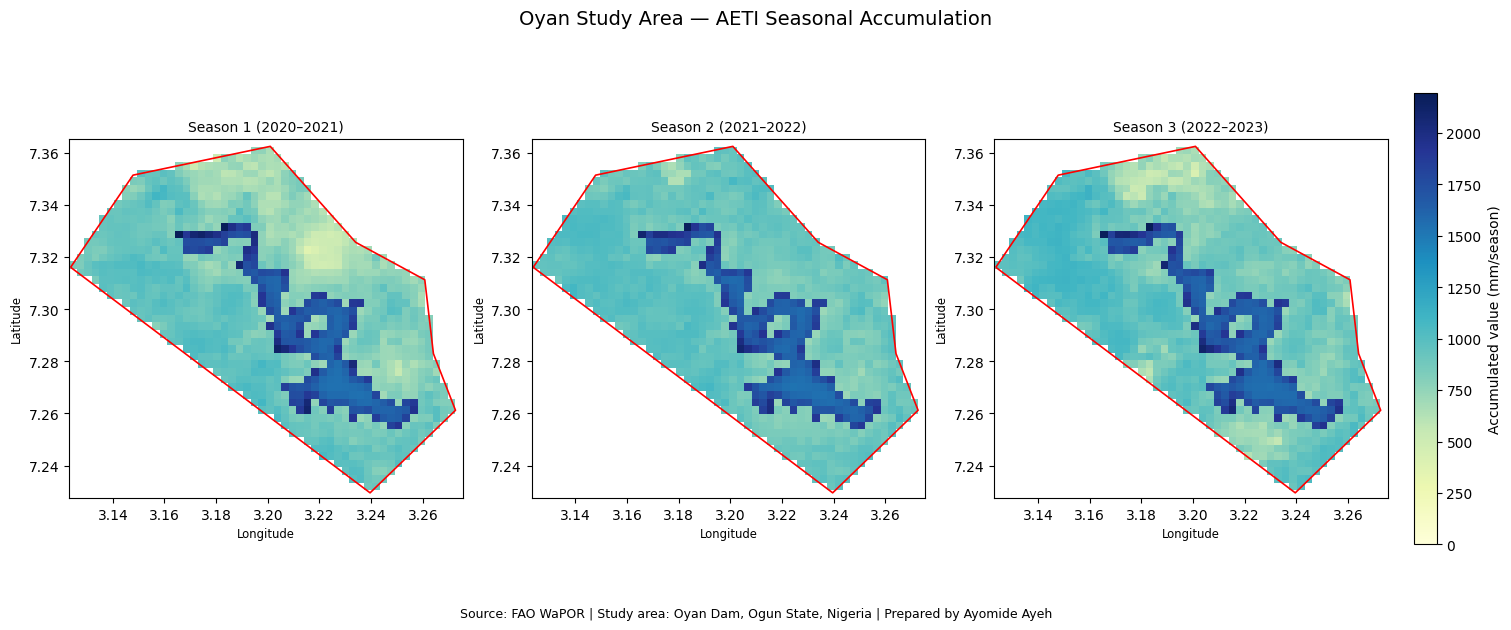

Saved figure: /content/Oyan_Analysis_Results/Three_Season_Figures/Oyan_AETI_Three_Season_Maps.png


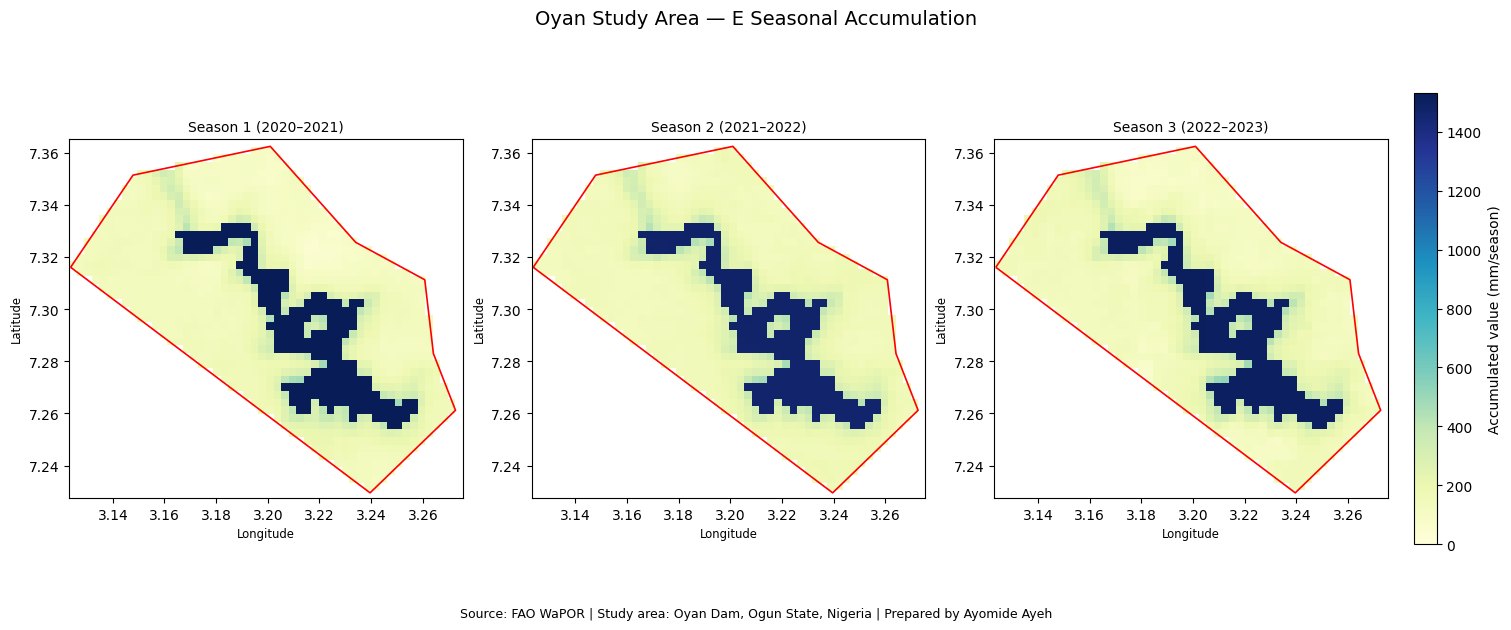

Saved figure: /content/Oyan_Analysis_Results/Three_Season_Figures/Oyan_E_Three_Season_Maps.png


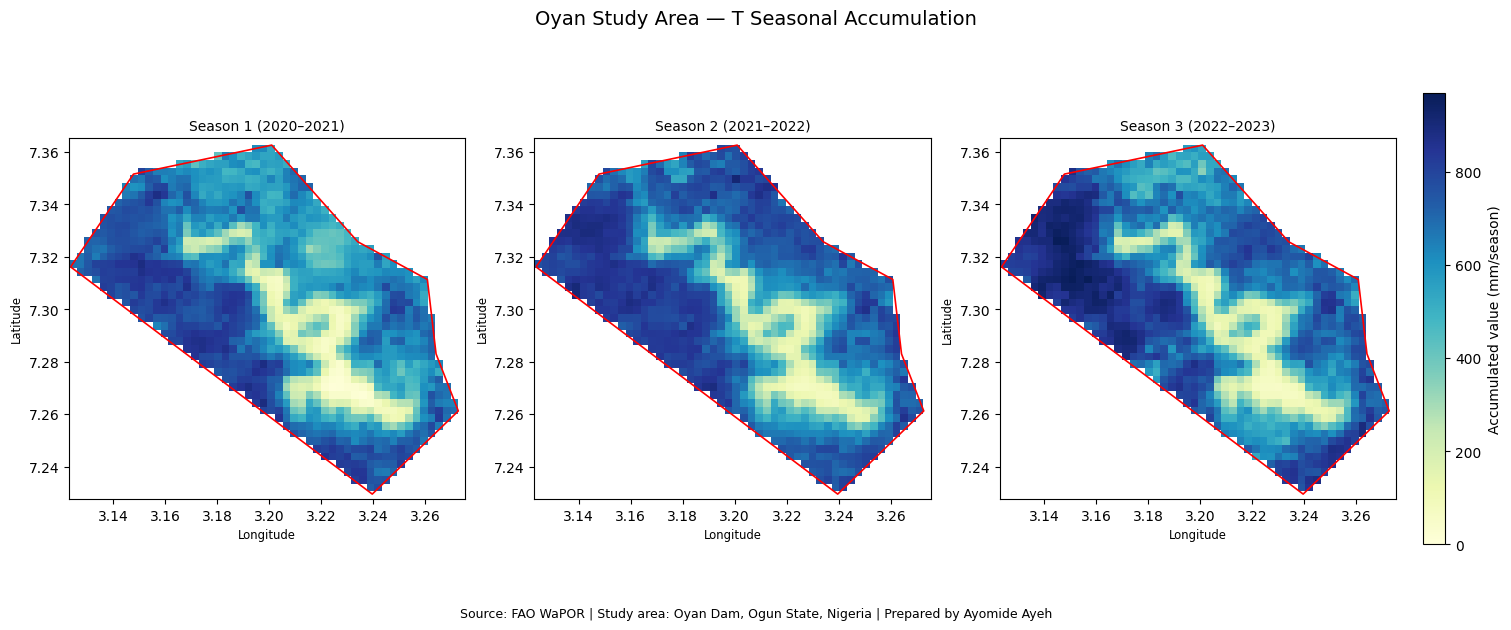

Saved figure: /content/Oyan_Analysis_Results/Three_Season_Figures/Oyan_T_Three_Season_Maps.png

Finished: 3 products, 3 seasons, boundary-masked outputs.


In [65]:

import os
import glob
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from rasterio.features import geometry_mask
from rasterio.transform import array_bounds

# --------------------------------------------------
# 1. SETTINGS
# --------------------------------------------------
boundary_path = "/content/Oyan_Study_Area.geojson"
data_folder = "/content/content/output"
results_folder = "/content/Oyan_Analysis_Results"

raster_output = os.path.join(
    results_folder, "Three_Season_Masked_Rasters"
)
figure_output = os.path.join(
    results_folder, "Three_Season_Figures"
)
os.makedirs(raster_output, exist_ok=True)
os.makedirs(figure_output, exist_ok=True)

products = {
    "AETI": "L1-AETI-D",
    "E": "L1-E-D",
    "T": "L1-T-D"
}

seasons = {
    "Season 1 (2020–2021)": ("2020-10-01", "2021-09-30"),
    "Season 2 (2021–2022)": ("2021-10-01", "2022-09-30"),
    "Season 3 (2022–2023)": ("2022-10-01", "2023-09-30")
}

boundary = gpd.read_file(boundary_path)
if boundary.empty or not boundary.geometry.is_valid.all():
    raise ValueError("Oyan boundary is empty or invalid.")

# --------------------------------------------------
# 2. HELPER: READ AND SUM DEKADAL FILES
# --------------------------------------------------
def get_raster_date(path):
    """Extract YYYY-MM-DD from the filename."""
    import re
    match = re.search(r"(\d{4}-\d{2}-\d{2})\.tif$", path)
    return pd.to_datetime(match.group(1)) if match else None

def get_valid_data(path):
    with rasterio.open(path) as src:
        data = src.read(1, masked=True)
        values = data.astype("float64").filled(np.nan)
        valid = ~np.ma.getmaskarray(data) & np.isfinite(values)

        if src.nodata is not None:
            valid &= values != src.nodata

        return values, valid, src.profile.copy(), src.crs, src.transform

# --------------------------------------------------
# 3. PROCESS EACH PRODUCT AND SEASON
# --------------------------------------------------
summary = []
season_rasters = {}

for product, subfolder in products.items():
    product_folder = os.path.join(data_folder, subfolder)
    files = sorted(glob.glob(os.path.join(product_folder, "*.tif")))

    dated_files = [
        (get_raster_date(f), f)
        for f in files
        if get_raster_date(f) is not None
    ]

    if not dated_files:
        raise FileNotFoundError(f"No dated TIFF files found in {product_folder}")

    for season_name, (start_date, end_date) in seasons.items():
        start = pd.Timestamp(start_date)
        end = pd.Timestamp(end_date)

        selected_files = [
            (date, path) for date, path in dated_files
            if start <= date <= end
        ]

        if not selected_files:
            raise ValueError(
                f"No rasters found for {product}, {season_name}"
            )

        # Load reference grid
        first_path = selected_files[0][1]
        with rasterio.open(first_path) as src:
            profile = src.profile.copy()
            transform = src.transform
            crs = src.crs
            height, width = src.height, src.width

            boundary_projected = boundary.to_crs(crs)
            inside = geometry_mask(
                boundary_projected.geometry,
                out_shape=(height, width),
                transform=transform,
                invert=True,
                all_touched=False
            )

        total = np.zeros((height, width), dtype="float64")
        valid_any = np.zeros((height, width), dtype=bool)

        for date, path in selected_files:
            with rasterio.open(path) as src:
                if (
                    src.crs != crs
                    or src.transform != transform
                    or src.width != width
                    or src.height != height
                ):
                    raise ValueError(
                        f"Grid mismatch for {path}; regrid before summing."
                    )

                data = src.read(1, masked=True)
                values = data.astype("float64").filled(np.nan)
                valid = (
                    ~np.ma.getmaskarray(data)
                    & np.isfinite(values)
                )

                if src.nodata is not None:
                    valid &= values != src.nodata

                # Accumulate valid dekadal values
                total[valid] += values[valid]
                valid_any |= valid

        # Keep only pixels inside the study boundary with valid data
        final_valid = inside & valid_any
        seasonal_total = np.where(final_valid, total, -9999.0)

        # Save masked seasonal accumulated raster
        safe_season = season_name.replace(" ", "_").replace("–", "-")
        output_tif = os.path.join(
            raster_output,
            f"Oyan_{product}_{safe_season}_Sum.tif"
        )

        profile.update(
            dtype="float32",
            count=1,
            nodata=-9999.0,
            compress="deflate"
        )

        with rasterio.open(output_tif, "w", **profile) as dst:
            dst.write(seasonal_total.astype("float32"), 1)
            dst.update_tags(
                product=product,
                season=season_name,
                start_date=start_date,
                end_date=end_date,
                units="mm/season",
                source="FAO WaPOR",
                prepared_by="Ayomide Ayeh"
            )

        season_rasters[(product, season_name)] = (
            seasonal_total, transform, crs
        )

        vals = seasonal_total[final_valid]
        summary.append({
            "Product": product,
            "Season": season_name,
            "Start_Date": start_date,
            "End_Date": end_date,
            "Dekadal_Rasters_Used": len(selected_files),
            "Valid_Pixels": int(vals.size),
            "Minimum_mm_season": round(float(vals.min())),
            "Maximum_mm_season": round(float(vals.max())),
            "Mean_mm_season": round(float(vals.mean())),
            "Std_Dev_mm_season": round(float(vals.std()))
        })

        print(
            f"Completed {product} | {season_name} | "
            f"{len(selected_files)} dekadal rasters"
        )

# --------------------------------------------------
# 4. SAVE SUMMARY STATISTICS
# --------------------------------------------------
summary_df = pd.DataFrame(summary)
stat_columns = [
    "Minimum_mm_season", "Maximum_mm_season",
    "Mean_mm_season", "Std_Dev_mm_season"
]
summary_df[stat_columns] = summary_df[stat_columns].round().astype(int)

csv_path = os.path.join(
    results_folder, "Oyan_Three_Season_Boundary_Statistics.csv"
)
summary_df.to_csv(csv_path, index=False)

print("\nTHREE-SEASON BOUNDARY STATISTICS")
print(summary_df.to_string(index=False))
print("\nSaved statistics:", csv_path)

# --------------------------------------------------
# 5. CREATE ONE 1 x 3 MAP FOR EACH PRODUCT
# --------------------------------------------------
season_names = list(seasons.keys())

for product in products:
    arrays = [
        season_rasters[(product, name)][0]
        for name in season_names
    ]
    all_values = np.concatenate([
        arr[np.isfinite(arr) & (arr != -9999)]
        for arr in arrays
    ])

    vmax = float(all_values.max())
    fig, axes = plt.subplots(
        1, 3, figsize=(15, 6), constrained_layout=True
    )

    image = None

    for ax, season_name, arr in zip(axes, season_names, arrays):
        with rasterio.open(
            os.path.join(
                raster_output,
                f"Oyan_{product}_{season_name.replace(' ', '_').replace('–', '-')}_Sum.tif"
            )
        ) as src:
            bounds = src.bounds
            image = ax.imshow(
                np.ma.masked_equal(arr, -9999),
                extent=[
                    bounds.left, bounds.right,
                    bounds.bottom, bounds.top
                ],
                origin="upper",
                cmap="YlGnBu",
                vmin=0,
                vmax=vmax
            )

            boundary.to_crs(src.crs).boundary.plot(
                ax=ax, color="red", linewidth=1.2
            )

        ax.set_title(season_name, fontsize=10)
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")

    fig.suptitle(
        f"Oyan Study Area — {product} Seasonal Accumulation",
        fontsize=14
    )
    cbar = fig.colorbar(
        image, ax=axes.tolist(), shrink=0.8, pad=0.02
    )
    cbar.set_label("Accumulated value (mm/season)")

    fig.text(
        0.5, -0.02,
        "Source: FAO WaPOR | Study area: Oyan Dam, Ogun State, Nigeria | "
        "Prepared by Ayomide Ayeh",
        ha="center", fontsize=9
    )

    output_png = os.path.join(
        figure_output,
        f"Oyan_{product}_Three_Season_Maps.png"
    )
    fig.savefig(output_png, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved figure:", output_png)

print("\nFinished: 3 products, 3 seasons, boundary-masked outputs.")


In [66]:

import os
import zipfile
from google.colab import files

# Folder containing the three-season maps
source_dir = "/content/Oyan_Analysis_Results/Three_Season_Figures"

# Map filenames
map_files = [
    "Oyan_AETI_Three_Season_Maps.png",
    "Oyan_E_Three_Season_Maps.png",
    "Oyan_T_Three_Season_Maps.png"
]

# ZIP output path
zip_path = "/content/Oyan_Three_Season_Maps.zip"

# Create ZIP archive
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in map_files:
        filepath = os.path.join(source_dir, filename)

        if os.path.exists(filepath):
            zipf.write(filepath, arcname=filename)
            print(f"Added: {filename}")
        else:
            print(f"WARNING: File not found: {filepath}")

# Download the ZIP file
if os.path.exists(zip_path):
    print("\nDownloading your seasonal maps...")
    files.download(zip_path)


Added: Oyan_AETI_Three_Season_Maps.png
Added: Oyan_E_Three_Season_Maps.png
Added: Oyan_T_Three_Season_Maps.png



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Seasonal raster folder: /content/Oyan_Analysis_Results/Three_Season_Masked_Rasters
Raster files found: 9
Could not uniquely match E, Season_1_2020-2021: 2 files
Could not uniquely match E, Season_2_2021-2022: 2 files
Could not uniquely match E, Season_3_2022-2023: 2 files
Could not uniquely match T, Season_1_2020-2021: 2 files
Could not uniquely match T, Season_2_2021-2022: 2 files
Could not uniquely match T, Season_3_2022-2023: 2 files

FINAL ZONAL STATISTICS
Product             Season     Units  Valid_Pixels  Minimum  Maximum  Mean  Std_Dev
   AETI Season_1_2020-2021 mm/season          1224      362     2195   989      359
   AETI Season_2_2021-2022 mm/season          1224      628     2162  1049      313
   AETI Season_3_2022-2023 mm/season          1224      265     1378   598      226

CSV saved in: /content/Oyan_Analysis_Results/Final_Zonal_Statistics


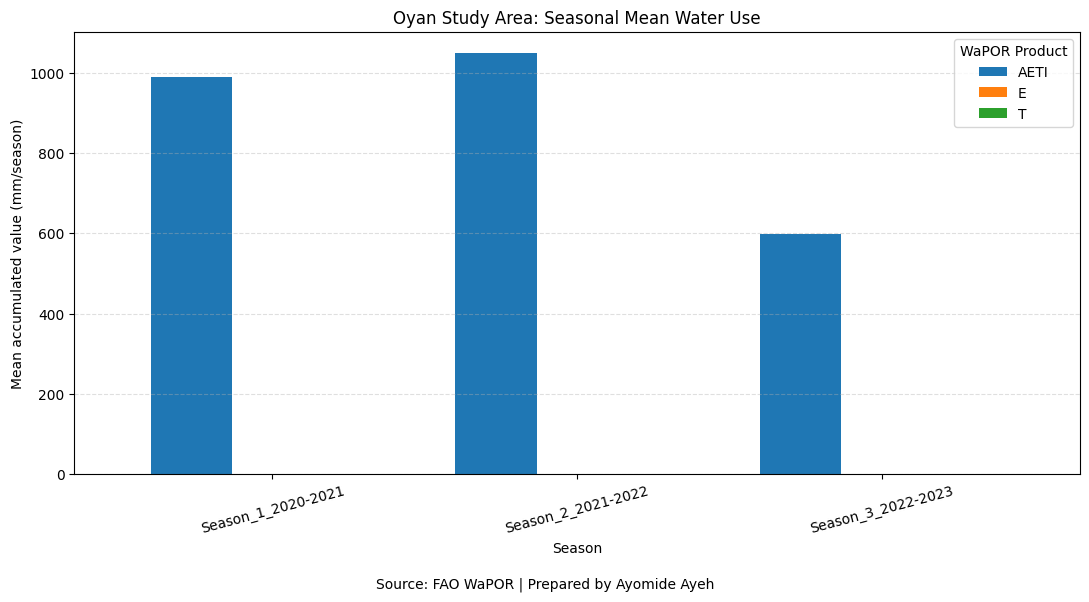

Comparison chart saved: /content/Oyan_Analysis_Results/Final_Zonal_Statistics/Figures/Oyan_Seasonal_Mean_Zonal_Comparison.png


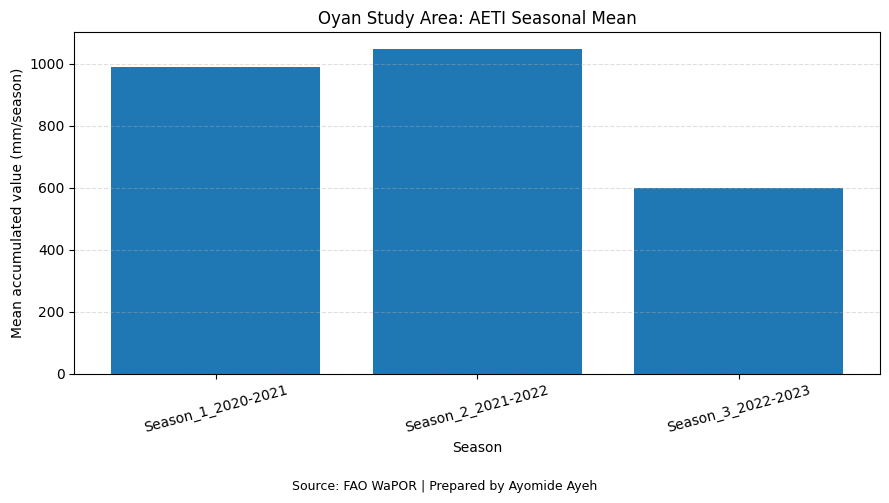

Saved: /content/Oyan_Analysis_Results/Final_Zonal_Statistics/Figures/Oyan_AETI_Seasonal_Mean.png

FINAL ZONAL STATISTICS AND FIGURES COMPLETE.


In [39]:

import os
import glob
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from rasterio.features import geometry_mask

# --------------------------------------------------
# 1. PATHS
# --------------------------------------------------
boundary_path = "/content/Oyan_Study_Area.geojson"

raster_folder = (
    "/content/Oyan_Analysis_Results/"
    "Three_Season_Masked_Rasters"
)

# Match the folder used by the previous seasonal script
if not os.path.isdir(raster_folder):
    raster_folder = (
        "/content/Oyan_Analysis_Results/"
        "Three_Season_Masked_Rasters"
    )

results_folder = "/content/Oyan_Analysis_Results"
stats_folder = os.path.join(results_folder, "Final_Zonal_Statistics")
figures_folder = os.path.join(stats_folder, "Figures")

os.makedirs(stats_folder, exist_ok=True)
os.makedirs(figures_folder, exist_ok=True)

products = ["AETI", "E", "T"]

season_labels = [
    "Season_1_2020-2021",
    "Season_2_2021-2022",
    "Season_3_2022-2023"
]

# --------------------------------------------------
# 2. LOAD BOUNDARY
# --------------------------------------------------
boundary = gpd.read_file(boundary_path)

if boundary.empty or not boundary.geometry.is_valid.all():
    raise ValueError("Oyan boundary is empty or invalid.")

# --------------------------------------------------
# 3. LOCATE SEASONAL RASTERS
# --------------------------------------------------
files = sorted(glob.glob(os.path.join(raster_folder, "*.tif")))

print("Seasonal raster folder:", raster_folder)
print("Raster files found:", len(files))

if len(files) != 9:
    raise ValueError(
        "Expected 9 seasonal rasters (3 products x 3 seasons). "
        "Check the raster folder and filenames before continuing."
    )

# --------------------------------------------------
# 4. CALCULATE ZONAL STATISTICS
# --------------------------------------------------
results = []

for product in products:
    for season in season_labels:

        # Flexible matching for product and season label
        product_files = [
            f for f in files
            if product in os.path.basename(f)
            and season.split("_")[1] in os.path.basename(f)
        ]

        # Use filename matching that tolerates hyphen variations
        season_number = season.split("_")[1]
        product_files = [
            f for f in files
            if product in os.path.basename(f)
            and f"Season_{season_number}" in os.path.basename(f)
        ]

        if len(product_files) != 1:
            print(
                f"Could not uniquely match {product}, {season}: "
                f"{len(product_files)} files"
            )
            continue

        raster_path = product_files[0]

        with rasterio.open(raster_path) as src:
            boundary_projected = boundary.to_crs(src.crs)

            inside = geometry_mask(
                boundary_projected.geometry,
                out_shape=(src.height, src.width),
                transform=src.transform,
                invert=True,
                all_touched=False
            )

            data = src.read(1, masked=True)
            values = data.astype("float64").filled(np.nan)

            valid = (
                inside
                & ~np.ma.getmaskarray(data)
                & np.isfinite(values)
            )

            if src.nodata is not None:
                valid &= values != src.nodata

            selected = values[valid]

            if selected.size == 0:
                print("No valid pixels:", raster_path)
                continue

            results.append({
                "Product": product,
                "Season": season,
                "Units": "mm/season",
                "Valid_Pixels": int(selected.size),
                "Minimum": round(float(selected.min())),
                "Maximum": round(float(selected.max())),
                "Mean": round(float(selected.mean())),
                "Std_Dev": round(float(selected.std(ddof=0)))
            })

# --------------------------------------------------
# 5. SAVE STATISTICS TABLE
# --------------------------------------------------
df = pd.DataFrame(results)

if df.empty:
    raise ValueError(
        "No statistics were generated. Check the seasonal filenames."
    )

for col in ["Minimum", "Maximum", "Mean", "Std_Dev"]:
    df[col] = df[col].astype(int)

df.to_csv(
    os.path.join(stats_folder, "Oyan_Final_Zonal_Statistics.csv"),
    index=False
)

print("\nFINAL ZONAL STATISTICS")
print(df.to_string(index=False))
print("\nCSV saved in:", stats_folder)

# --------------------------------------------------
# 6. CREATE SEASONAL MEAN COMPARISON CHART
# --------------------------------------------------
pivot = df.pivot(
    index="Season",
    columns="Product",
    values="Mean"
)

# Preserve chronological season order
pivot = pivot.reindex(season_labels)
pivot = pivot.reindex(columns=products)

ax = pivot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

ax.set_title("Oyan Study Area: Seasonal Mean Water Use")
ax.set_xlabel("Season")
ax.set_ylabel("Mean accumulated value (mm/season)")
ax.tick_params(axis="x", labelrotation=15)
ax.legend(title="WaPOR Product")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.figtext(
    0.5, 0.01,
    "Source: FAO WaPOR | Prepared by Ayomide Ayeh",
    ha="center", fontsize=10
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

chart_path = os.path.join(
    figures_folder,
    "Oyan_Seasonal_Mean_Zonal_Comparison.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Comparison chart saved:", chart_path)

# --------------------------------------------------
# 7. CREATE SEPARATE CHART FOR EACH PRODUCT
# --------------------------------------------------
for product in products:
    subset = df[df["Product"] == product].copy()

    if subset.empty:
        continue

    subset["Season"] = pd.Categorical(
        subset["Season"],
        categories=season_labels,
        ordered=True
    )
    subset = subset.sort_values("Season")

    plt.figure(figsize=(9, 5))
    plt.bar(
        subset["Season"].astype(str),
        subset["Mean"]
    )

    plt.title(f"Oyan Study Area: {product} Seasonal Mean")
    plt.xlabel("Season")
    plt.ylabel("Mean accumulated value (mm/season)")
    plt.xticks(rotation=15)
    plt.grid(axis="y", linestyle="--", alpha=0.4)

    plt.figtext(
        0.5, 0.01,
        "Source: FAO WaPOR | Prepared by Ayomide Ayeh",
        ha="center", fontsize=9
    )

    plt.tight_layout(rect=[0, 0.05, 1, 1])

    chart_path = os.path.join(
        figures_folder,
        f"Oyan_{product}_Seasonal_Mean.png"
    )

    plt.savefig(chart_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", chart_path)

print("\nFINAL ZONAL STATISTICS AND FIGURES COMPLETE.")


In [69]:

import os
import glob
import rasterio
import pandas as pd

base_dir = "/content/Oyan_Analysis_Results"

# --------------------------------------------------
# 1. Inspect the dekadal time-series CSV files
# --------------------------------------------------
csv_files = {
    "AETI": f"{base_dir}/Dekadal_Time_Series/AETI_Dekadal_Time_Series.csv",
    "E":    f"{base_dir}/Dekadal_Time_Series/E_Dekadal_Time_Series.csv",
    "T":    f"{base_dir}/Dekadal_Time_Series/T_Dekadal_Time_Series.csv",
}

print("=" * 65)
print("DEKADAL TIME-SERIES CSV INSPECTION")
print("=" * 65)

for product, path in csv_files.items():
    if not os.path.exists(path):
        print(f"\n{product}: CSV not found: {path}")
        continue

    df = pd.read_csv(path)

    print(f"\n{product}")
    print("Columns:", df.columns.tolist())
    print("Number of rows:", len(df))
    print(df.head(3).to_string(index=False))

# --------------------------------------------------
# 2. Inspect seasonal raster metadata
# --------------------------------------------------
raster_dir = f"{base_dir}/Three_Season_Masked_Rasters"

print("\n" + "=" * 65)
print("SEASONAL RASTER METADATA")
print("=" * 65)

for product in ["AETI", "E", "T"]:
    pattern = os.path.join(
        raster_dir, f"Oyan_{product}_Season_1*Sum.tif"
    )
    matches = glob.glob(pattern)

    if not matches:
        print(f"\n{product}: No matching seasonal raster found.")
        continue

    raster_path = matches[0]

    with rasterio.open(raster_path) as src:
        print(f"\n{product}: {os.path.basename(raster_path)}")
        print("Data type:", src.dtypes)
        print("Band count:", src.count)
        print("Raster units tag:", src.tags().get("units", "Not specified"))
        print("All dataset tags:", src.tags())
        print("Band 1 tags:", src.tags(1))
        print("Scale:", src.scales)
        print("Offset:", src.offsets)
        print("NoData:", src.nodata)
        print("Value range:", src.statistics(1))


DEKADAL TIME-SERIES CSV INSPECTION

AETI
Columns: ['Date', 'Product', 'Mean', 'Valid_Pixels', 'File']
Number of rows: 108
      Date Product      Mean  Valid_Pixels                                                          File
2020-10-01    AETI 28.984477          1224 Oyan_Study_Area_L1-AETI-D_NONE_dekad_converted_2020-10-01.tif
2020-10-11    AETI 29.995915          1224 Oyan_Study_Area_L1-AETI-D_NONE_dekad_converted_2020-10-11.tif
2020-10-21    AETI 33.243546          1224 Oyan_Study_Area_L1-AETI-D_NONE_dekad_converted_2020-10-21.tif

E
Columns: ['Date', 'Product', 'Mean', 'Valid_Pixels', 'File']
Number of rows: 108
      Date Product      Mean  Valid_Pixels                                                       File
2020-10-01       E  9.754902          1224 Oyan_Study_Area_L1-E-D_NONE_dekad_converted_2020-10-01.tif
2020-10-11       E 10.207516          1224 Oyan_Study_Area_L1-E-D_NONE_dekad_converted_2020-10-11.tif
2020-10-21       E 11.589542          1224 Oyan_Study_Area_L1-E-D_NO

/tmp/ipykernel_3045/504416693.py:64: RasterioDeprecationWarning: statistics() will be removed in 2.0.0. Please switch to stats().
  print("Value range:", src.statistics(1))


In [70]:

import os
import glob
import rasterio
import numpy as np

search_root = "/content"

print("=" * 65)
print("ORIGINAL DEKADAL RASTER UNIT CHECK")
print("=" * 65)

for product in ["AETI", "E", "T"]:
    pattern = os.path.join(
        search_root,
        "**",
        f"*L1-{product}-D*dekad_converted_2020-10-01.tif"
    )

    matches = glob.glob(pattern, recursive=True)

    if not matches:
        print(f"\n{product}: Original converted raster not found.")
        continue

    raster_path = matches[0]

    with rasterio.open(raster_path) as src:
        data = src.read(1, masked=True)
        valid = data.compressed()

        print(f"\nProduct: {product}")
        print("File:", raster_path)
        print("Unit tag:", src.tags().get("units", "Not specified"))
        print("Dataset tags:", src.tags())
        print("Band tags:", src.tags(1))
        print("Scale:", src.scales)
        print("Offset:", src.offsets)
        print("Valid pixel minimum:", float(np.min(valid)) if valid.size else None)
        print("Valid pixel maximum:", float(np.max(valid)) if valid.size else None)
        print("Valid pixel mean:", float(np.mean(valid)) if valid.size else None)


ORIGINAL DEKADAL RASTER UNIT CHECK

Product: AETI
File: /content/content/output/L1-AETI-D/Oyan_Study_Area_L1-AETI-D_NONE_dekad_converted_2020-10-01.tif
Unit tag: Not specified
Dataset tags: {'AREA_OR_POINT': 'Area'}
Band tags: {'end_date': '2020-10-10', 'long_name': 'Actual EvapoTranspiration and Interception', 'number_of_days': '10', 'original_units': 'mm/day', 'overview': 'NONE', 'start_date': '2020-10-01', 'temporal_resolution': 'Dekad', 'units': 'mm/dekad', 'units_conversion_factor': '10'}
Scale: (1.0,)
Offset: (0.0,)
Valid pixel minimum: 0.0
Valid pixel maximum: 56.0
Valid pixel mean: 28.96078431372549

Product: E
File: /content/content/output/L1-E-D/Oyan_Study_Area_L1-E-D_NONE_dekad_converted_2020-10-01.tif
Unit tag: Not specified
Dataset tags: {'AREA_OR_POINT': 'Area'}
Band tags: {'end_date': '2020-10-10', 'long_name': 'Evaporation', 'number_of_days': '10', 'original_units': 'mm/day', 'overview': 'NONE', 'start_date': '2020-10-01', 'temporal_resolution': 'Dekad', 'units': 'mm/de

Study area boundary loaded successfully.
Boundary CRS: EPSG:4326

Processing AETI...


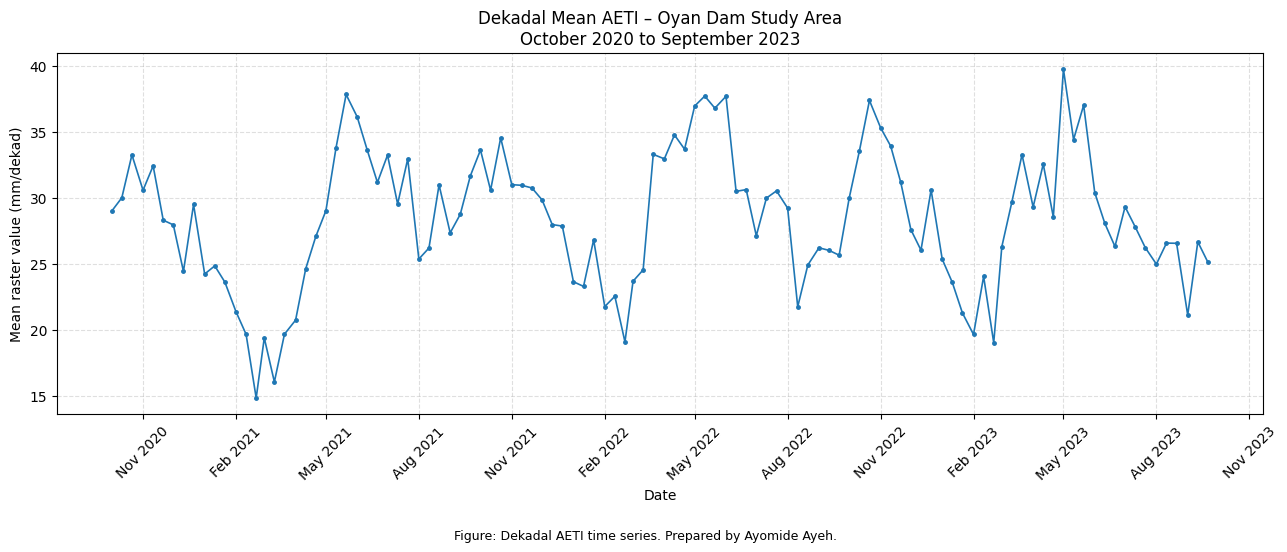

Raster files processed: 108
CSV saved: /content/Oyan_Analysis_Results/Dekadal_Time_Series/AETI_Dekadal_Time_Series.csv
Figure saved: /content/Oyan_Analysis_Results/Dekadal_Time_Series/Figures/AETI_Dekadal_Time_Series.png

Processing E...


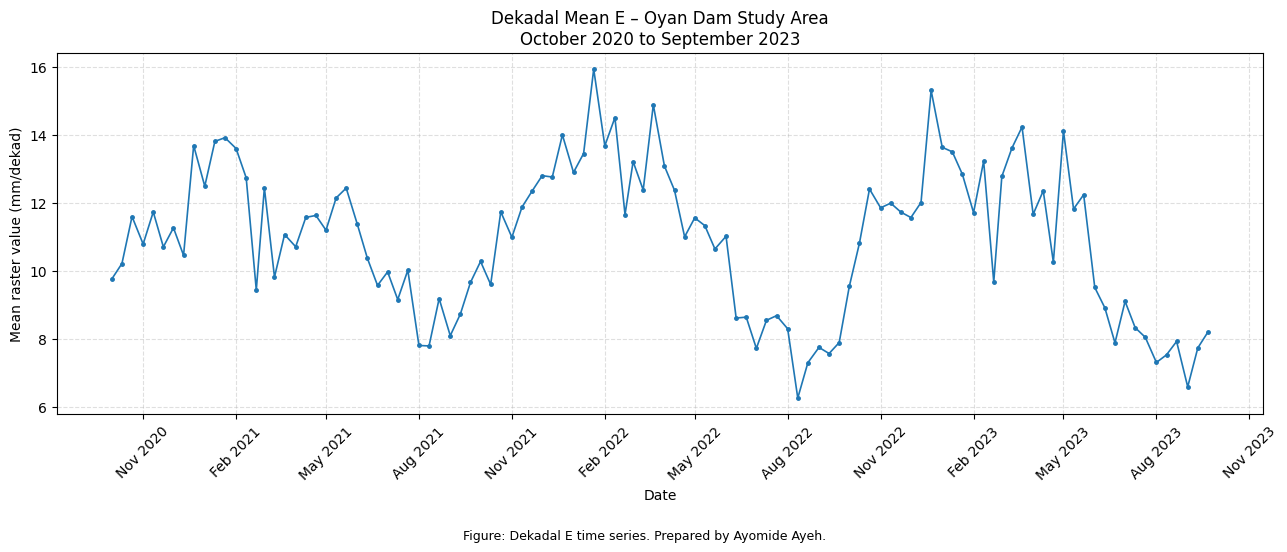

Raster files processed: 108
CSV saved: /content/Oyan_Analysis_Results/Dekadal_Time_Series/E_Dekadal_Time_Series.csv
Figure saved: /content/Oyan_Analysis_Results/Dekadal_Time_Series/Figures/E_Dekadal_Time_Series.png

Processing T...


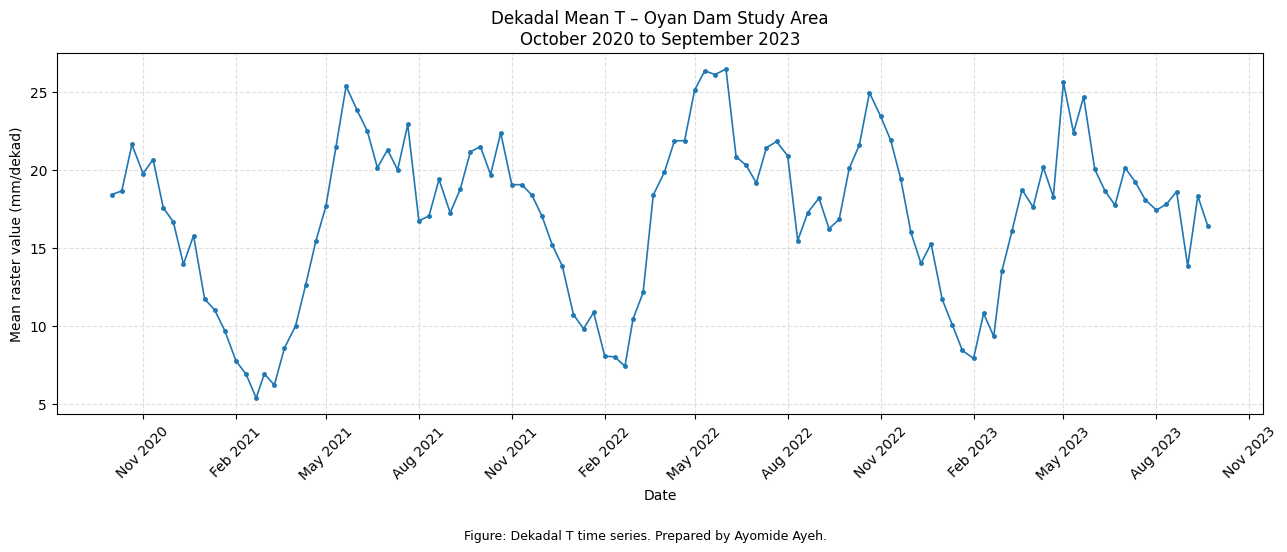

Raster files processed: 108
CSV saved: /content/Oyan_Analysis_Results/Dekadal_Time_Series/T_Dekadal_Time_Series.csv
Figure saved: /content/Oyan_Analysis_Results/Dekadal_Time_Series/Figures/T_Dekadal_Time_Series.png

PROCESSING COMPLETE
Combined CSV: /content/Oyan_Analysis_Results/Dekadal_Time_Series/All_Products_Dekadal_Time_Series.csv
Figures folder: /content/Oyan_Analysis_Results/Dekadal_Time_Series/Figures

Records by product:
Product
AETI    108
E       108
T       108
dtype: int64


In [71]:

# ============================================================
# DEKADAL TIME-SERIES ANALYSIS OF WaPOR LEVEL 1 DATA
# Study area: Oyan Dam, Ogun State, Nigeria
# Period: 1 October 2020 - 30 April 2023
# Prepared by Ayomide Ayeh
# ============================================================

import os
import glob
import re
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from rasterio.features import geometry_mask

# ------------------------------------------------------------
# 1. DEFINE INPUT AND OUTPUT PATHS
# ------------------------------------------------------------

boundary_path = "/content/Oyan_Study_Area.geojson"
data_folder = "/content/content/output"

output_folder = "/content/Oyan_Analysis_Results/Dekadal_Time_Series"
figure_folder = os.path.join(output_folder, "Figures")

os.makedirs(figure_folder, exist_ok=True)

products = {
    "AETI": os.path.join(data_folder, "L1-AETI-D"),
    "E":    os.path.join(data_folder, "L1-E-D"),
    "T":    os.path.join(data_folder, "L1-T-D")
}

start_date = pd.Timestamp("2020-10-01")
end_date = pd.Timestamp("2023-09-30")

# ------------------------------------------------------------
# 2. LOAD THE STUDY AREA BOUNDARY
# ------------------------------------------------------------

boundary = gpd.read_file(boundary_path)

if boundary.empty:
    raise ValueError("The study area boundary file is empty.")

boundary = boundary[boundary.geometry.notnull()]
boundary = boundary[~boundary.geometry.is_empty]

if boundary.empty:
    raise ValueError("No valid geometries found in the boundary file.")

print("Study area boundary loaded successfully.")
print("Boundary CRS:", boundary.crs)

# ------------------------------------------------------------
# 3. FUNCTION TO EXTRACT DATE FROM RASTER FILENAME
# ------------------------------------------------------------

def extract_date(filename):
    """
    Supports dates such as YYYY-MM-DD and YYYYMMDD.
    """
    basename = os.path.basename(filename)

    match = re.search(r"(?<!\d)(\d{4}-\d{2}-\d{2})(?!\d)", basename)

    if match:
        return pd.to_datetime(match.group(1), errors="coerce")

    match = re.search(r"(?<!\d)(\d{8})(?!\d)", basename)

    if match:
        return pd.to_datetime(match.group(1), format="%Y%m%d",
                              errors="coerce")

    return pd.NaT

# ------------------------------------------------------------
# 4. FUNCTION TO CALCULATE MEAN FOR EACH DEKAD
# ------------------------------------------------------------

def calculate_dekadal_mean(raster_path, boundary):
    with rasterio.open(raster_path) as src:

        if src.crs is None:
            raise ValueError(f"Raster has no CRS: {raster_path}")

        # Reproject boundary to match raster CRS
        boundary_raster_crs = boundary.to_crs(src.crs)

        geometries = [
            geom.__geo_interface__
            for geom in boundary_raster_crs.geometry
            if geom is not None and not geom.is_empty
        ]

        # Read raster values
        raster = src.read(1, masked=True).astype("float64")

        # Build a mask using pixel-centre inclusion
        inside = geometry_mask(
            geometries,
            out_shape=(src.height, src.width),
            transform=src.transform,
            invert=True,
            all_touched=False
        )

        # Respect NoData and exclude pixels outside the boundary
        values = raster.compressed()

        raster_array = raster.filled(np.nan)
        valid = inside & np.isfinite(raster_array)

        if src.nodata is not None:
            valid &= raster_array != src.nodata

        selected = raster_array[valid]

        if selected.size == 0:
            return np.nan, 0

        # Apply raster scale if defined in the metadata
        scale = src.scales[0] if src.scales else 1.0
        offset = src.offsets[0] if src.offsets else 0.0

        selected = selected * scale + offset

        return float(np.mean(selected)), int(selected.size)

# ------------------------------------------------------------
# 5. PROCESS EACH PRODUCT
# ------------------------------------------------------------

all_results = []

for product, folder in products.items():

    print(f"\nProcessing {product}...")

    if not os.path.isdir(folder):
        print(f"Folder not found: {folder}")
        continue

    raster_files = (
        glob.glob(os.path.join(folder, "*.tif")) +
        glob.glob(os.path.join(folder, "*.tiff")) +
        glob.glob(os.path.join(folder, "*.TIF"))
    )

    records = []

    for raster_path in sorted(set(raster_files)):

        date = extract_date(raster_path)

        if pd.isna(date):
            continue

        if not (start_date <= date <= end_date):
            continue

        try:
            mean_value, pixel_count = calculate_dekadal_mean(
                raster_path, boundary
            )

            records.append({
                "Date": date,
                "Product": product,
                "Mean": mean_value,
                "Valid_Pixels": pixel_count,
                "File": os.path.basename(raster_path)
            })

        except Exception as error:
            print(f"Error processing {raster_path}: {error}")

    if not records:
        print(
            f"No matching rasters found for {product}. "
            "Check folder paths and filename dates."
        )
        continue

    product_df = pd.DataFrame(records).sort_values("Date")

    # Save individual product time-series data
    csv_path = os.path.join(
        output_folder, f"{product}_Dekadal_Time_Series.csv"
    )
    product_df.to_csv(csv_path, index=False)

    # --------------------------------------------------------
    # 6. PLOT THE DEKADAL TIME SERIES
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(13, 5.5))

    ax.plot(
        product_df["Date"],
        product_df["Mean"],
        linewidth=1.2,
        marker="o",
        markersize=2.5
    )

    ax.set_title(
        f"Dekadal Mean {product} – Oyan Dam Study Area\n"
        f"October 2020 to September 2023"
    )
    ax.set_xlabel("Date")
    ax.set_ylabel("Mean raster value (mm/dekad)")
    ax.grid(True, linestyle="--", alpha=0.4)

    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    plt.xticks(rotation=45)

    fig.text(
        0.5, 0.01,
        f"Figure: Dekadal {product} time series. Prepared by Ayomide Ayeh.",
        ha="center", fontsize=9
    )

    plt.tight_layout(rect=[0, 0.05, 1, 1])

    figure_path = os.path.join(
        figure_folder, f"{product}_Dekadal_Time_Series.png"
    )
    plt.savefig(figure_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    all_results.append(product_df)

    print("Raster files processed:", len(product_df))
    print("CSV saved:", csv_path)
    print("Figure saved:", figure_path)

# ------------------------------------------------------------
# 7. SAVE A COMBINED CSV
# ------------------------------------------------------------

if all_results:
    combined_df = pd.concat(all_results, ignore_index=True)

    combined_csv = os.path.join(
        output_folder, "All_Products_Dekadal_Time_Series.csv"
    )
    combined_df.to_csv(combined_csv, index=False)

    print("\nPROCESSING COMPLETE")
    print("Combined CSV:", combined_csv)
    print("Figures folder:", figure_folder)
    print("\nRecords by product:")
    print(combined_df.groupby("Product").size())
else:
    print(
        "\nNo results were generated. Check that the raster folders "
        "and filename date patterns match the script."
    )


In [72]:

import os
import zipfile
from google.colab import files

# Folder containing the figures
figures_dir = (
    "/content/Oyan_Analysis_Results/"
    "Dekadal_Time_Series/Figures"
)

# Graph filenames
graph_files = [
    "AETI_Dekadal_Time_Series.png",
    "E_Dekadal_Time_Series.png",
    "T_Dekadal_Time_Series.png"
]

# ZIP file destination
zip_path = "/content/Oyan_Dekadal_Time_Series_Graphs.zip"

# Create ZIP archive
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in graph_files:
        filepath = os.path.join(figures_dir, filename)

        if os.path.exists(filepath):
            zipf.write(filepath, arcname=filename)
            print(f"Added: {filename}")
        else:
            print(f"WARNING: File not found: {filepath}")

# Download to your computer
if os.path.exists(zip_path):
    print("\nDownloading dekadal time-series graphs...")
    files.download(zip_path)


Added: AETI_Dekadal_Time_Series.png
Added: E_Dekadal_Time_Series.png
Added: T_Dekadal_Time_Series.png



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

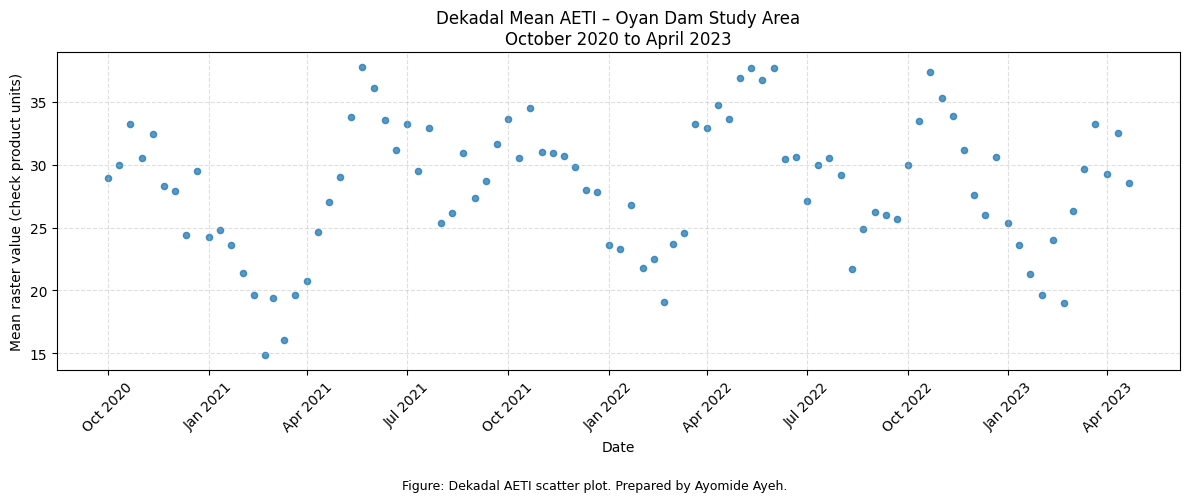

AETI scatter plot saved: /content/Oyan_Analysis_Results/Dekadal_Time_Series/Figures/AETI_Dekadal_Scatter_Plot.png


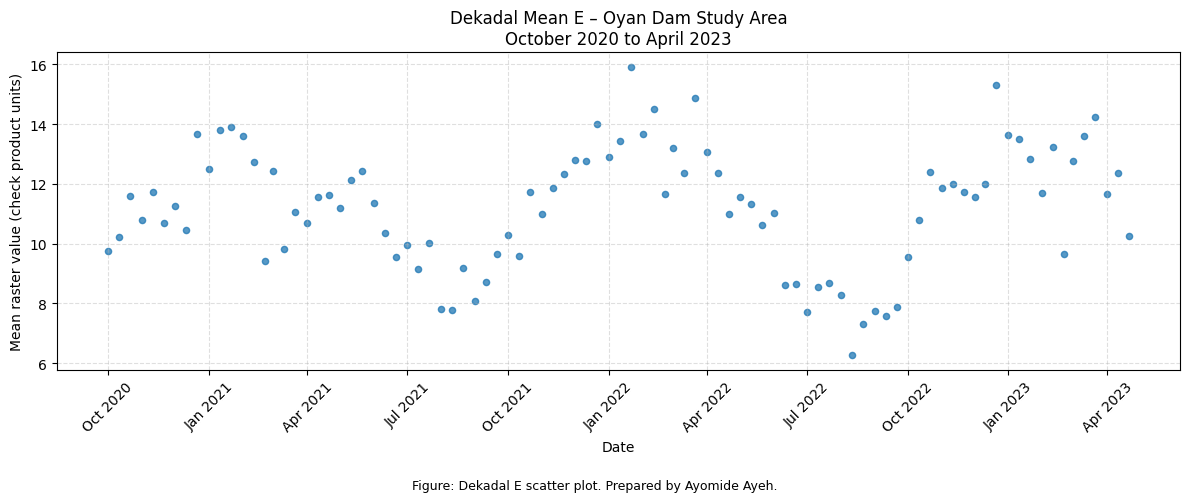

E scatter plot saved: /content/Oyan_Analysis_Results/Dekadal_Time_Series/Figures/E_Dekadal_Scatter_Plot.png


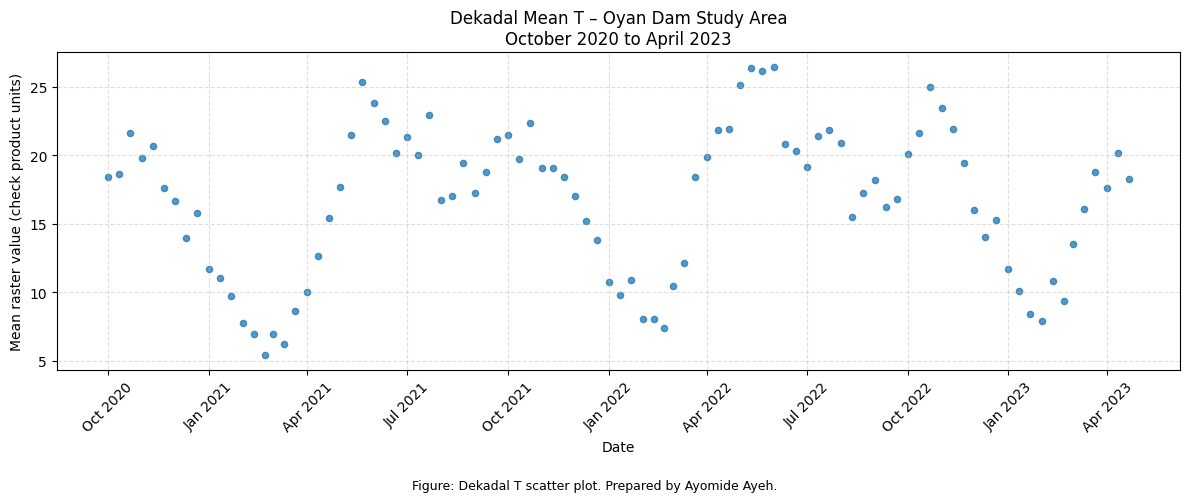

T scatter plot saved: /content/Oyan_Analysis_Results/Dekadal_Time_Series/Figures/T_Dekadal_Scatter_Plot.png


In [42]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Folder containing the previously saved time-series CSV files
output_folder = "/content/Oyan_Analysis_Results/Dekadal_Time_Series"
figure_folder = os.path.join(output_folder, "Figures")
os.makedirs(figure_folder, exist_ok=True)

products = ["AETI", "E", "T"]

for product in products:

    csv_path = os.path.join(
        output_folder,
        f"{product}_Dekadal_Time_Series.csv"
    )

    if not os.path.exists(csv_path):
        print(f"CSV not found for {product}: {csv_path}")
        continue

    df = pd.read_csv(csv_path, parse_dates=["Date"])
    df = df.dropna(subset=["Date", "Mean"]).sort_values("Date")

    if df.empty:
        print(f"No valid data available for {product}.")
        continue

    # Create a separate scatter plot for each product
    fig, ax = plt.subplots(figsize=(12, 5))

    ax.scatter(
        df["Date"],
        df["Mean"],
        s=20,
        alpha=0.75
    )

    ax.set_title(
        f"Dekadal Mean {product} – Oyan Dam Study Area\n"
        "October 2020 to April 2023"
    )
    ax.set_xlabel("Date")
    ax.set_ylabel("Mean raster value (check product units)")
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, linestyle="--", alpha=0.4)

    fig.text(
        0.5, 0.01,
        f"Figure: Dekadal {product} scatter plot. "
        "Prepared by Ayomide Ayeh.",
        ha="center",
        fontsize=9
    )

    plt.tight_layout(rect=[0, 0.05, 1, 1])

    save_path = os.path.join(
        figure_folder,
        f"{product}_Dekadal_Scatter_Plot.png"
    )

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"{product} scatter plot saved: {save_path}")


In [46]:

import os
import glob
import re
import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
from rasterio.mask import mask

# --------------------------------------------------
# 1. Define paths
# --------------------------------------------------
raster_folder = (
    "/content/Oyan_Analysis_Results/"
    "Three_Season_Masked_Rasters"
)

boundary_path = "/content/Oyan_Study_Area.geojson"

output_folder = (
    "/content/Oyan_Analysis_Results/"
    "Final_Zonal_Statistics"
)

os.makedirs(output_folder, exist_ok=True)

# --------------------------------------------------
# 2. Read study area boundary
# --------------------------------------------------
gdf = gpd.read_file(boundary_path)

# --------------------------------------------------
# 3. Define exact seasonal labels
# --------------------------------------------------
season_labels = {
    "Season_1_(2020-2021)": "Season 1 (2020–2021)",
    "Season_2_(2021-2022)": "Season 2 (2021–2022)",
    "Season_3_(2022-2023)": "Season 3 (2022–2023)"
}

products = ["AETI", "E", "T"]
results = []

# --------------------------------------------------
# 4. Process all seasonal rasters
# --------------------------------------------------
raster_files = sorted(
    glob.glob(os.path.join(raster_folder, "*.tif"))
)

print("Total raster files found:", len(raster_files))

for raster_path in raster_files:
    filename = os.path.basename(raster_path)

    # Match the product using the exact filename prefix
    product_match = re.match(r"Oyan_(AETI|E|T)_", filename)

    if not product_match:
        print("Skipping unrecognized filename:", filename)
        continue

    product = product_match.group(1)

    # Identify the season from the filename
    season_key = next(
        (
            key for key in season_labels
            if key in filename
        ),
        None
    )

    if season_key is None:
        print("Could not identify season:", filename)
        continue

    with rasterio.open(raster_path) as src:
        boundary = gdf.to_crs(src.crs)

        # Mask raster to the study area
        masked_data, _ = mask(
            src,
            boundary.geometry,
            crop=False,
            filled=False
        )

        # Use the first raster band
        band = masked_data[0]

        # Exclude NoData and non-finite values
        values = band.compressed().astype("float64")
        values = values[np.isfinite(values)]

        if values.size == 0:
            print("No valid pixels:", filename)
            continue

        # Apply scale and offset only when metadata specifies them.
        # If rasters are already scaled, do not apply them again.
        scale = src.scales[0] if src.scales else 1.0
        offset = src.offsets[0] if src.offsets else 0.0

        if scale != 1.0 or offset != 0.0:
            values = values * scale + offset

        results.append({
            "Product": product,
            "Season": season_labels[season_key],
            "Mean": float(np.mean(values)),
            "Minimum": float(np.min(values)),
            "Maximum": float(np.max(values)),
            "Std_Dev": float(np.std(values, ddof=0)),
            "Valid_Pixels": int(values.size),
            "Raster_File": filename
        })

        print(
            f"{product} | {season_labels[season_key]} | "
            f"Valid pixels: {values.size}"
        )

# --------------------------------------------------
# 5. Save and verify results
# --------------------------------------------------
stats_df = pd.DataFrame(results)

if stats_df.empty:
    raise ValueError(
        "No zonal statistics were calculated. "
        "Check the raster folder and boundary."
    )

stats_df = stats_df.sort_values(
    ["Product", "Season"]
).reset_index(drop=True)

csv_path = os.path.join(
    output_folder,
    "Oyan_Three_Season_Zonal_Statistics.csv"
)

stats_df.to_csv(csv_path, index=False)

print("\nStatistics saved to:", csv_path)
print("\nProduct counts:")
print(stats_df["Product"].value_counts())

print("\nComplete zonal statistics:")
print(stats_df.to_string(index=False))

# Check that all 9 product-season combinations were processed
if len(stats_df) != 9:
    print(
        "\nWARNING: Expected 9 records but obtained",
        len(stats_df)
    )
else:
    print("\nSUCCESS: All 9 seasonal raster statistics were calculated.")


Total raster files found: 9
AETI | Season 1 (2020–2021) | Valid pixels: 1224
AETI | Season 2 (2021–2022) | Valid pixels: 1224
AETI | Season 3 (2022–2023) | Valid pixels: 1224
E | Season 1 (2020–2021) | Valid pixels: 1224
E | Season 2 (2021–2022) | Valid pixels: 1224
E | Season 3 (2022–2023) | Valid pixels: 1224
T | Season 1 (2020–2021) | Valid pixels: 1224
T | Season 2 (2021–2022) | Valid pixels: 1224
T | Season 3 (2022–2023) | Valid pixels: 1224

Statistics saved to: /content/Oyan_Analysis_Results/Final_Zonal_Statistics/Oyan_Three_Season_Zonal_Statistics.csv

Product counts:
Product
AETI    3
E       3
T       3
Name: count, dtype: int64

Complete zonal statistics:
Product               Season        Mean    Minimum     Maximum    Std_Dev  Valid_Pixels                            Raster_File
   AETI Season 1 (2020–2021)  988.806292 362.399994 2195.100098 358.585987          1224 Oyan_AETI_Season_1_(2020-2021)_Sum.tif
   AETI Season 2 (2021–2022) 1048.519526 628.299988 2162.500000 313.2

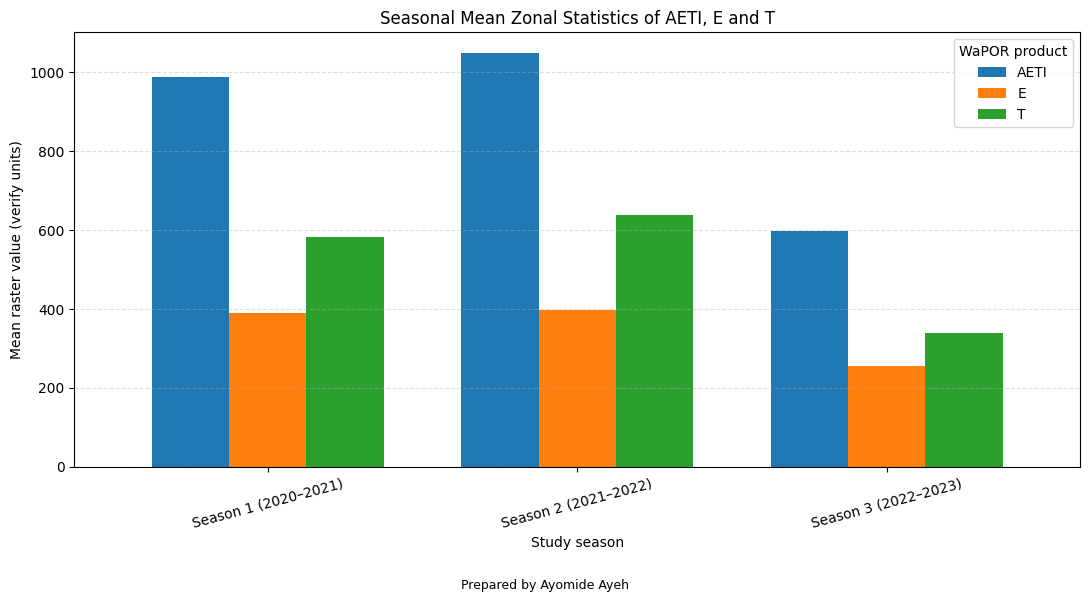

Figure saved: /content/Oyan_Analysis_Results/Final_Zonal_Statistics/Figures/All_Products_Seasonal_Mean_Comparison.png


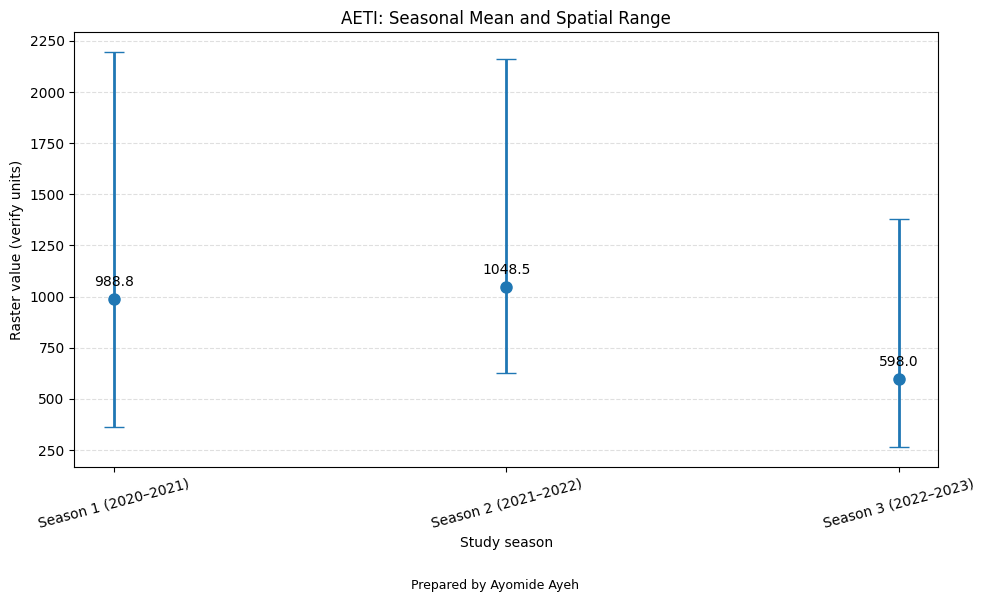

Figure saved: /content/Oyan_Analysis_Results/Final_Zonal_Statistics/Figures/AETI_Seasonal_Zonal_Statistics.png


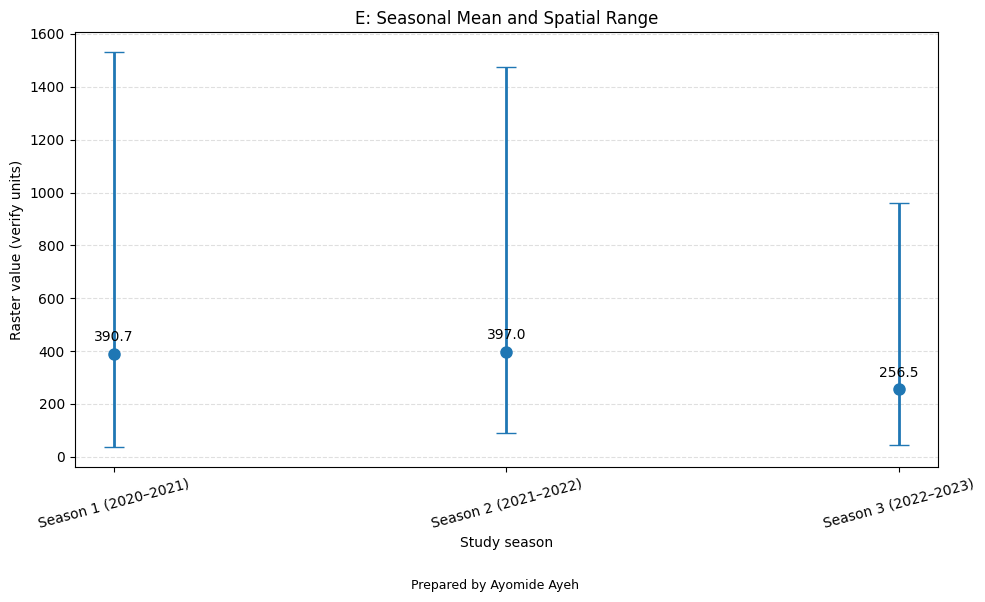

Figure saved: /content/Oyan_Analysis_Results/Final_Zonal_Statistics/Figures/E_Seasonal_Zonal_Statistics.png


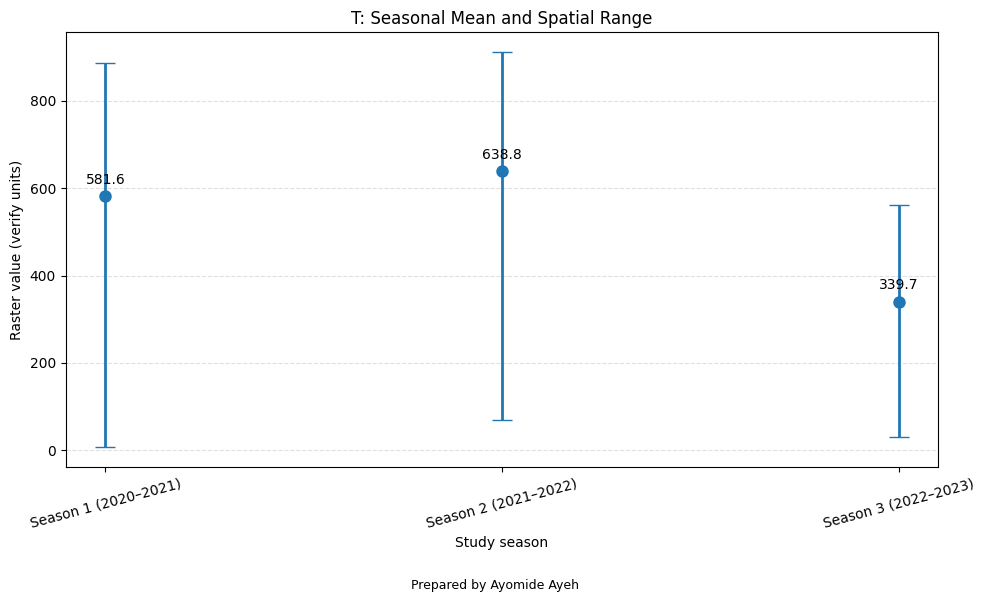

Figure saved: /content/Oyan_Analysis_Results/Final_Zonal_Statistics/Figures/T_Seasonal_Zonal_Statistics.png

All four zonal-statistics figures have been generated.


In [47]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------
output_folder = (
    "/content/Oyan_Analysis_Results/"
    "Final_Zonal_Statistics"
)
figure_folder = os.path.join(output_folder, "Figures")
csv_path = os.path.join(
    output_folder,
    "Oyan_Three_Season_Zonal_Statistics.csv"
)

os.makedirs(figure_folder, exist_ok=True)

df = pd.read_csv(csv_path)

season_order = [
    "Season 1 (2020–2021)",
    "Season 2 (2021–2022)",
    "Season 3 (2022–2023)"
]
product_order = ["AETI", "E", "T"]

df["Season"] = pd.Categorical(
    df["Season"],
    categories=season_order,
    ordered=True
)

df = df.sort_values(["Product", "Season"])

# --------------------------------------------------
# 2. Figure 1: Compare seasonal mean values
# --------------------------------------------------
pivot = df.pivot(
    index="Season",
    columns="Product",
    values="Mean"
).reindex(index=season_order, columns=product_order)

ax = pivot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.set_title(
    "Seasonal Mean Zonal Statistics of AETI, E and T"
)
ax.set_xlabel("Study season")
ax.set_ylabel("Mean raster value (verify units)")
ax.legend(title="WaPOR product")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.figtext(
    0.5, 0.01,
    "Prepared by Ayomide Ayeh",
    ha="center",
    fontsize=9
)
plt.tight_layout(rect=[0, 0.05, 1, 1])

path = os.path.join(
    figure_folder,
    "All_Products_Seasonal_Mean_Comparison.png"
)
plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()
print("Figure saved:", path)

# --------------------------------------------------
# 3. Figures 2–4: Individual product range charts
# --------------------------------------------------
for product in product_order:
    subset = (
        df[df["Product"] == product]
        .set_index("Season")
        .reindex(season_order)
    )

    x = np.arange(len(season_order))
    means = subset["Mean"].to_numpy()
    minimums = subset["Minimum"].to_numpy()
    maximums = subset["Maximum"].to_numpy()

    # Error bars show minimum-to-maximum range
    lower_error = means - minimums
    upper_error = maximums - means

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.errorbar(
        x,
        means,
        yerr=np.vstack([lower_error, upper_error]),
        fmt="o",
        capsize=7,
        markersize=8,
        linewidth=2
    )

    ax.set_xticks(x)
    ax.set_xticklabels(season_order, rotation=15)
    ax.set_title(
        f"{product}: Seasonal Mean and Spatial Range"
    )
    ax.set_xlabel("Study season")
    ax.set_ylabel("Raster value (verify units)")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    # Label the mean values
    for i, mean in enumerate(means):
        ax.annotate(
            f"{mean:.1f}",
            (x[i], mean),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center"
        )

    fig.text(
        0.5, 0.01,
        "Prepared by Ayomide Ayeh",
        ha="center",
        fontsize=9
    )
    fig.tight_layout(rect=[0, 0.05, 1, 1])

    filename = f"{product}_Seasonal_Zonal_Statistics.png"
    path = os.path.join(figure_folder, filename)

    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Figure saved:", path)

print("\nAll four zonal-statistics figures have been generated.")


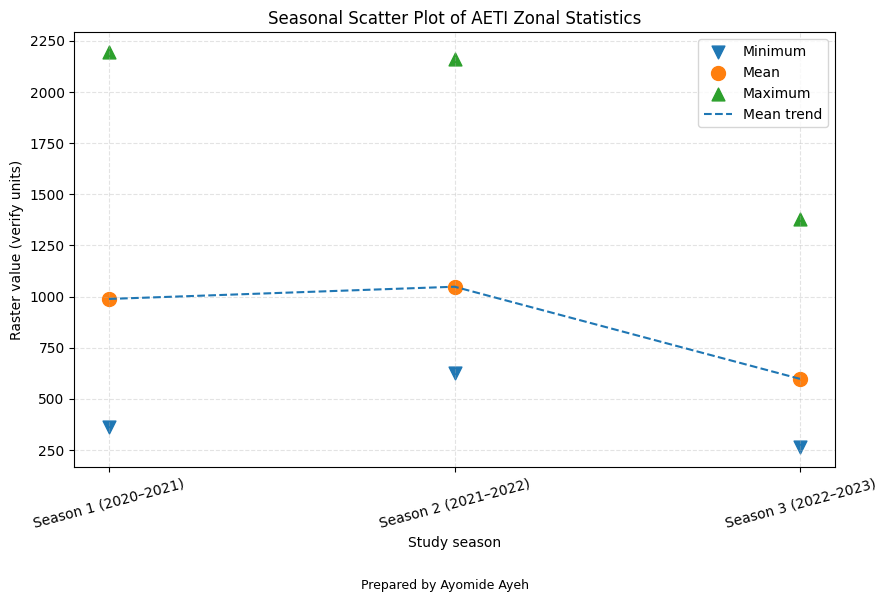

Figure saved: /content/Oyan_Analysis_Results/Final_Zonal_Statistics/Figures/AETI_Seasonal_Zonal_Statistics_Scatter.png


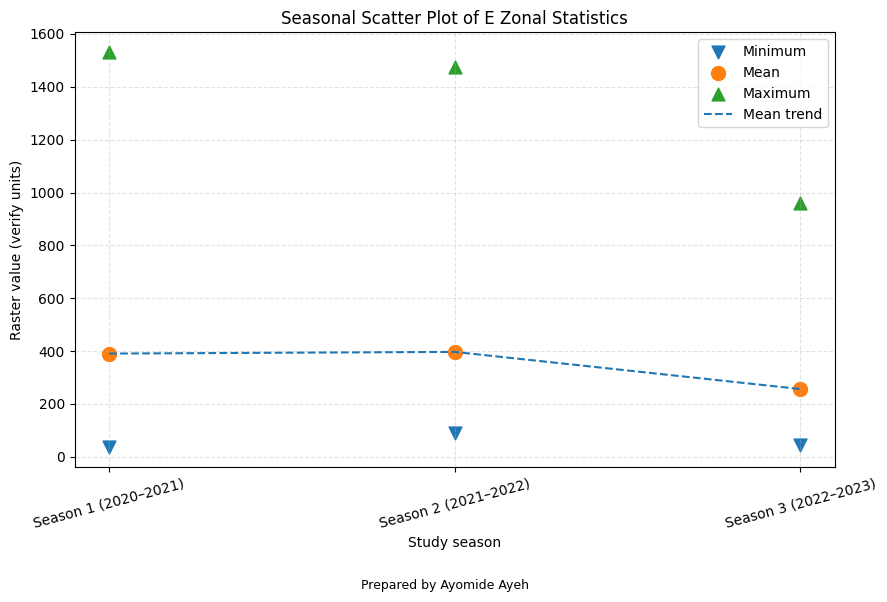

Figure saved: /content/Oyan_Analysis_Results/Final_Zonal_Statistics/Figures/E_Seasonal_Zonal_Statistics_Scatter.png


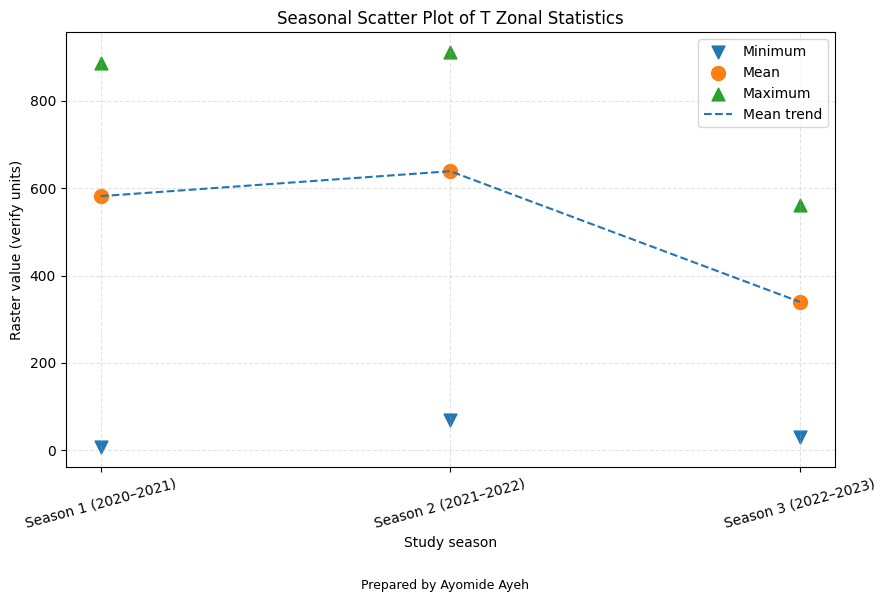

Figure saved: /content/Oyan_Analysis_Results/Final_Zonal_Statistics/Figures/T_Seasonal_Zonal_Statistics_Scatter.png

All three seasonal scatter plots have been generated.


In [48]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------------
# 1. Define paths
# --------------------------------------------------
base_folder = "/content/Oyan_Analysis_Results/Final_Zonal_Statistics"

csv_path = os.path.join(
    base_folder,
    "Oyan_Three_Season_Zonal_Statistics.csv"
)

figure_folder = os.path.join(base_folder, "Figures")
os.makedirs(figure_folder, exist_ok=True)

# --------------------------------------------------
# 2. Load zonal statistics
# --------------------------------------------------
df = pd.read_csv(csv_path)

season_order = [
    "Season 1 (2020–2021)",
    "Season 2 (2021–2022)",
    "Season 3 (2022–2023)"
]

products = ["AETI", "E", "T"]

df["Season"] = pd.Categorical(
    df["Season"],
    categories=season_order,
    ordered=True
)

df = df.sort_values("Season")

# --------------------------------------------------
# 3. Create one scatter plot for each product
# --------------------------------------------------
for product in products:
    subset = (
        df[df["Product"] == product]
        .set_index("Season")
        .reindex(season_order)
    )

    x = np.arange(1, len(season_order) + 1)

    fig, ax = plt.subplots(figsize=(9, 6))

    # Plot minimum, mean and maximum as separate series
    ax.scatter(
        x, subset["Minimum"],
        label="Minimum",
        marker="v",
        s=85
    )

    ax.scatter(
        x, subset["Mean"],
        label="Mean",
        marker="o",
        s=100
    )

    ax.scatter(
        x, subset["Maximum"],
        label="Maximum",
        marker="^",
        s=85
    )

    # Connect the mean points to show the seasonal trend
    ax.plot(
        x, subset["Mean"],
        linestyle="--",
        linewidth=1.5,
        label="Mean trend"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(season_order, rotation=15)
    ax.set_xlabel("Study season")
    ax.set_ylabel("Raster value (verify units)")
    ax.set_title(
        f"Seasonal Scatter Plot of {product} Zonal Statistics"
    )

    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.35)

    fig.text(
        0.5, 0.01,
        "Prepared by Ayomide Ayeh",
        ha="center",
        fontsize=9
    )

    fig.tight_layout(rect=[0, 0.05, 1, 1])

    output_path = os.path.join(
        figure_folder,
        f"{product}_Seasonal_Zonal_Statistics_Scatter.png"
    )

    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Figure saved:", output_path)

print("\nAll three seasonal scatter plots have been generated.")


<div class="alert alert-success">


⚡ **EXERCISE 2**:

Write code to produce the monthly sum of AETI for April 2023, find the min, max and mean

Note down the values (rounded to the nearest integer, no decimals), you will need to enter these in the MOOC quiz!

</div>

In [ ]:
## Enter your code here
#Loop through the correct files to produce a sum for April 2023



# Print the min, max and mean values



### **Step 6** - More detailed temporal aggregation
So far we have done aggregation for:
1.   all files available
2.   all files with an easily recognisable pattern in the file name     

We will now learn how to select **only files within a specified time period**, for example between the start and end of season.

To do this we will:


1.   Obtain a list of all dates for the availabile files as datetime objects
2.   Define a start and end date
3.   Select only files names for which the date falls between the start and end dates

To start we will get a list of the filenames and extract the date from the name: you can observe that the date is contained in the last 10 characters before the file extension.


In [ ]:
fnames = glob.glob('/content/content/output/L3-AETI-D/*.tif')
fnames

Let's see how we can isolate the date on one filename:

In [ ]:
path1 = fnames[0]
path1

You should see a path that looks something like:     

`/content/content/output/L3-AETI-D/Wad_Helal.GEZ_L3-AETI-D_NONE_dekad_converted_2022-11-21.tif`

We want to extract the date, e.g. in this case: '2022-11-21'     
Because all of the file names have the same formatting, ending with the date and .tif, we can simply extract the corresponding characters by counting their position from the end of the string:    
*   the date is located between the character located 14 positions from the end, and the character located 4 positions from the end.





In [ ]:
date0 = path1[-14:-4] #[-14:-4] selects characters in the string: starts at the 14th from the end, to 4th from the end
print(date0)

This is now a *string*. In oder to be able to do operations and comparisons between dates, we need to convert it to a datetime object. We can use the datetime library for this.
The datetime.strptime function allows us to go from a string to a datetime object, you can read the documentation [here](https://docs.python.org/3/library/datetime.html#strftime-strptime-behavior).

In [ ]:
date0 =  datetime.datetime.strptime(date0, '%Y-%m-%d')
date0

We can now produce a list with all the dates corresponding to our filenames:

In [ ]:
file_dates = []
for path0 in fnames:
  date0 = datetime.datetime.strptime(path0[-14:-4], '%Y-%m-%d')
  file_dates.append(date0)

In [ ]:
file_dates

We now have a list of datetimes. Note that this can be done more succintly with the following command:


```
[fname[-14:-4] for d in fnames]
```

We will now define the start and end dates of our season and find the files which are located between these dates:



In [ ]:
sos = datetime.datetime(2022,10,1) #start of season date, we use datetime.datetime to convert the year, month, day to a datetime object
eos = datetime.datetime(2023,2,28) #end of season date

Finally, we will check which dates from our list fall between the start and end date so we can select only the filenames corresponding to our season.      

**Note**: this is a simplified code and it does not a) Check whether all files from the season are present b) Deal with seasons which do not start and end at the beginning and end of a dekad

In [ ]:
selected_files = []
for i, date in enumerate(file_dates):
  if (date >= sos and date < eos):
    selected_files.append(fnames[i])
selected_files

It can be hard to check if all the files you want are there as they are not sorted, to adjust this you can simply run the following:

In [ ]:
sorted(selected_files)

If you are interested, another, more elegant way to achieve this result can be done with the following code:
```
mask = [(ds >= sos and ds < eos) for ds in file_dates]
fnames_array = np.array(fnames)
selected_files = fnames_array[mask]
```



<div class="alert alert-success">

⚡ **BONUS**:

Write code to produce the sum of AETI for the period between 21/01/2023 and 10/04/2023, find the min, max and mean



</div>

In [ ]:
## Enter your code here
#Create the list of files for the season between 21/01/2023 and 10/04/2023



#Compute the sum



# Print the min, max and mean values


**Review the data in QGIS**

Open the seasonal AETI file you have downloaded in QGIS as well as the shapefile for the area.  


<div class="alert alert-success">

⚡ **Quiz questions**:
  
1. What difference did you notice between the geojson vector file and the raster file from WaPOR?
>a.   The raster file is shifted     
b.   The polygon has a larger extent than the raster.    
c.   The raster has a larger extent than the polygon       

2. To what do you think this difference can be attributed to?
>a.   The raster and geojson have different projections     
b.   The WaPOR L3 data does not cover the whole extent of the geojson file.    
c.   The raster and geojson have different spatial resolutions    

⚡ You will need the answers to these questions in the MOOC Quiz

</div>